# Synapse RAG — Legal Contract Intelligence

### Dense Retrieval with Cross-Encoder Re-Ranking using Distilled Transformer Encoders

**Course:** Deep Learning (Semester 5) &nbsp;|&nbsp; **Project:** Synapse RAG &nbsp;|&nbsp; **Repository:** `synapse-rag`

---

## Abstract

Large Language Models hallucinate, which makes them unsafe for legal contract analysis, where a fabricated
clause carries real financial and legal liability. **Synapse RAG** constrains generation to retrieved
evidence using a two-stage neural retrieval pipeline over the **LegalBench-RAG** corpus:

1. **Stage 1 — Dense retrieval (bi-encoder).** `all-MiniLM-L6-v2`, a 6-layer distilled BERT encoder, maps
   queries and contract chunks into a shared 384-dimensional unit hypersphere. Qdrant's HNSW graph index
   makes nearest-neighbour search sub-linear in the number of vectors.
2. **Stage 2 — Re-ranking (cross-encoder).** `ms-marco-MiniLM-L-6-v2` jointly encodes
   `[CLS] query [SEP] chunk [SEP]`, so query tokens and document tokens attend to one another, producing
   far more accurate relevance logits over the shallow candidate pool.
3. **Grounded generation.** Each surviving child chunk is expanded to its full legal **parent clause**, the
   prompt is capped, and a Groq-hosted LLM answers strictly from that context with section-level citations.

## What this notebook does

Every output below is produced by **running the project's own production code** (`python/app/*`) against the
**live Qdrant index** built from LegalBench-RAG. Nothing is mocked or hard-coded. The notebook covers, in
order: the dataset, structural parsing and parent-child chunking, the bi-encoder, the cross-encoder, the
vector index, live two-stage retrieval, grounded generation, and the full set of quantitative results.

## Table of contents

| # | Section |
|---|---|
| 1 | [Environment and configuration](#1) |
| 2 | [Dataset: LegalBench-RAG](#2) |
| 3 | [Structural parsing and parent-child chunking](#3) |
| 4 | [Stage 1 — the bi-encoder](#4) |
| 5 | [Stage 2 — the cross-encoder re-ranker](#5) |
| 6 | [The vector index (Qdrant + HNSW)](#6) |
| 7 | [Live two-stage retrieval](#7) |
| 8 | [Parent expansion, prompt construction and grounded generation](#8) |
| 9 | [Results I — retrieval quality and re-ranking lift](#9) |
| 10 | [Results II — end-to-end faithfulness ablation](#10) |
| 11 | [Results III — multi-document fan-out reasoning](#11) |
| 12 | [Results IV — architecture validation suite](#12) |
| 13 | [Conclusions and future work](#13) |

<a id="1"></a>
## 1. Environment and configuration

The notebook runs on the project's own virtual environment (`python/venv`) so that it imports exactly the
model, chunking and retrieval code that the FastAPI backend serves in production.

> **Note on the vector store.** Qdrant runs here in *embedded* mode and takes an exclusive file lock on
> `python/qdrant_db`. Stop the FastAPI backend (`uvicorn app.main:app`) before running this notebook.
> Every operation performed below is **read-only** — no cell ingests, modifies or deletes a vector.

In [1]:
import json, os, sys, textwrap, warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)

# Locate the repository root from wherever the notebook is executed.
ROOT = Path.cwd()
while not (ROOT / "data").exists() or not (ROOT / "python" / "app").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Could not locate the synapse-rag repository root.")
    ROOT = ROOT.parent

PY_DIR, RESULTS_DIR = ROOT / "python", ROOT / "results"
sys.path.insert(0, str(PY_DIR))

from dotenv import load_dotenv
load_dotenv(ROOT / ".env")

from importlib.metadata import version as pkg_version

import torch, sentence_transformers

GROQ_MODEL = os.getenv("GROQ_MODEL") or "openai/gpt-oss-20b"   # app/rag.py default

print(f"Repository root : {ROOT}")
print(f"Python          : {sys.version.split()[0]}")
print(f"PyTorch         : {torch.__version__}  (CUDA available: {torch.cuda.is_available()})")
print(f"sentence-transf : {sentence_transformers.__version__}")
print(f"qdrant-client   : {pkg_version('qdrant-client')}")
print(f"langchain       : {pkg_version('langchain')}")
print(f"GROQ_API_KEY    : {'configured' if os.getenv('GROQ_API_KEY') else 'MISSING'}")
print(f"GROQ_MODEL      : {GROQ_MODEL}{'' if os.getenv('GROQ_MODEL') else '  (default, GROQ_MODEL unset)'}")

Repository root : C:\Users\Mithul\Academics\Semester - 5\Deep Learning\synapse-rag
Python          : 3.12.10
PyTorch         : 2.13.0+cpu  (CUDA available: False)
sentence-transf : 3.3.1
qdrant-client   : 1.12.0
langchain       : 0.3.14
GROQ_API_KEY    : configured
GROQ_MODEL      : openai/gpt-oss-20b  (default, GROQ_MODEL unset)


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt

%matplotlib inline

# One consistent, print-friendly visual style for every figure in this notebook.
INK, MUTED, GRID = "#1b1f2a", "#6b7280", "#e5e7eb"
C_STAGE1, C_STAGE2, C_ACCENT, C_WARN = "#4f6bed", "#1f9d8f", "#9a6bd8", "#d98b2b"

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 120, "figure.facecolor": "white",
    "axes.facecolor": "white", "axes.edgecolor": GRID, "axes.labelcolor": INK,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 26, "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False, "legend.fontsize": 9,
    "font.family": "DejaVu Sans", "font.size": 9,
})

def style(ax, title=None, sub=None, ylabel=None, pct=False):
    """Shared axis styling: horizontal-only grid, optional subtitle, optional % axis."""
    ax.set_axisbelow(True)
    ax.yaxis.grid(True)
    ax.xaxis.grid(False)
    if title:
        ax.set_title(title, loc="left")
        if sub:
            ax.text(0, 1.05, sub, transform=ax.transAxes, fontsize=9, color=MUTED, va="bottom")
    if ylabel:
        ax.set_ylabel(ylabel)
    if pct:
        ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(100, decimals=0))
    return ax

def label_bars(ax, bars, fmt="{:.1f}", dy=0.8):
    for b in bars:
        ax.annotate(fmt.format(b.get_height()), (b.get_x() + b.get_width() / 2, b.get_height() + dy),
                    ha="center", va="bottom", fontsize=8, color=INK)

print("Plot style configured.")

Plot style configured.


<a id="2"></a>
## 2. Dataset: LegalBench-RAG

**LegalBench-RAG** is a retrieval benchmark for the legal domain. Each record pairs a natural-language
question with the contract it came from *and* the exact character span of the gold answer. That span is what
makes retrieval-only evaluation possible: we can check whether the correct passage was retrieved,
independently of what the LLM then writes about it.

| Sub-corpus | Document type | Task |
|---|---|---|
| **CUAD** | Commercial contracts | Clause extraction |
| **MAUD** | M&A merger agreements | Deal-term analysis |
| **ContractNLI** | Non-disclosure agreements | Hypothesis verification |
| **PrivacyQA** | Privacy policies | Policy question answering |

In [3]:
with open(ROOT / "data" / "legalbench.json", encoding="utf-8") as f:
    qa_pairs = json.load(f)

rows = []
for item in qa_pairs:
    meta = item["metadata"]
    rows.append({
        "id": item["id"],
        "corpus": meta["corpus_file"].split("/")[0],
        "corpus_file": meta["corpus_file"].split("/")[-1],
        "query": meta["query"],
        "answer": meta["answer"],
        "num_snippets": meta.get("num_snippets", 0),
        "answer_chars": len(meta["answer"]),
    })
qa = pd.DataFrame(rows)

print(f"QA pairs           : {len(qa):,}")
print(f"Unique contracts   : {qa.corpus_file.nunique():,}")
print(f"Gold answer length : mean {qa.answer_chars.mean():.0f} chars | median {qa.answer_chars.median():.0f} | max {qa.answer_chars.max():,}")

summary = (qa.groupby("corpus")
             .agg(queries=("id", "size"), contracts=("corpus_file", "nunique"),
                  mean_snippets=("num_snippets", "mean"), mean_answer_chars=("answer_chars", "mean"))
             .sort_values("queries", ascending=False).round(2))
summary["share_%"] = (summary.queries / len(qa) * 100).round(1)
summary

QA pairs           : 5,373
Unique contracts   : 695
Gold answer length : mean 727 chars | median 472 | max 10,774


,queries,contracts,mean_snippets,mean_answer_chars,share_%
corpus,,,,,
cuad,3233,459,1.54,596.76,60.2
maud,1204,134,1.69,1188.25,22.4
contractnli,781,95,1.43,455.86,14.5
privacy_qa,155,7,2.45,1216.03,2.9


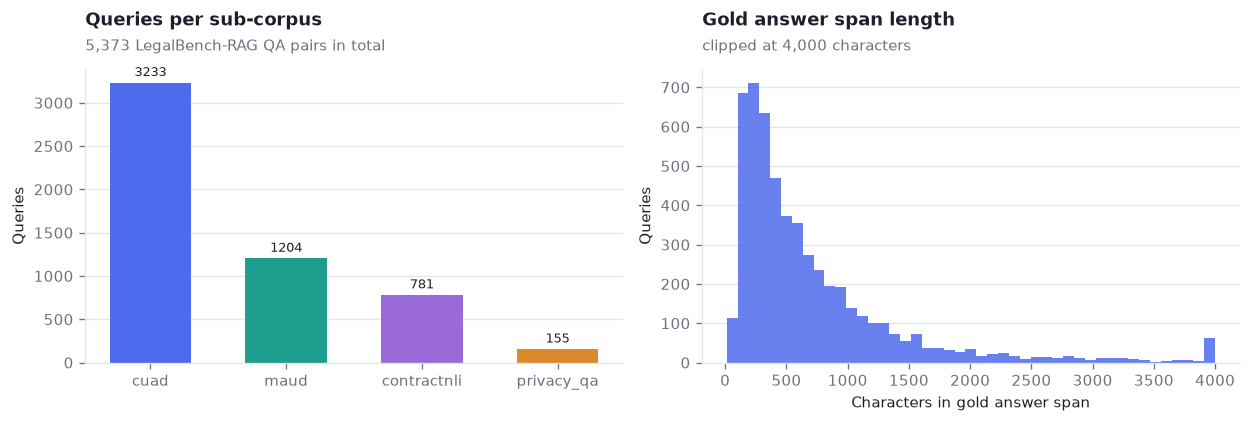

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.6))

order = summary.sort_values("queries", ascending=False)
bars = ax1.bar(order.index, order.queries, color=[C_STAGE1, C_STAGE2, C_ACCENT, C_WARN], width=0.6)
style(ax1, "Queries per sub-corpus", f"{len(qa):,} LegalBench-RAG QA pairs in total", "Queries")
label_bars(ax1, bars, "{:.0f}", dy=40)

ax2.hist(qa.answer_chars.clip(upper=4000), bins=45, color=C_STAGE1, alpha=0.85)
style(ax2, "Gold answer span length", "clipped at 4,000 characters", "Queries")
ax2.set_xlabel("Characters in gold answer span")

plt.tight_layout()
plt.show()

In [5]:
# One full record, to make the structure of a benchmark item concrete.
sample = qa_pairs[0]["metadata"]
print("QUERY       :", sample["query"])
print("SOURCE FILE :", sample["corpus_file"])
print("# SNIPPETS  :", sample.get("num_snippets"))
print("\nGOLD ANSWER SPAN:")
print(textwrap.fill(sample["answer"], 100))

QUERY       : Consider the Acquisition Agreement between Parent "Novo Nordisk A/S" and Target "Dicerna Pharmaceuticals, Inc."; What is the Type of Consideration
SOURCE FILE : maud/Dicerna_Pharmaceuticals_Inc_Novo_Nordisk_A_S.txt
# SNIPPETS  : 1

GOLD ANSWER SPAN:
(A) Purchaser shall commence a tender offer (as it may be amended from time to time as permitted
under this Agreement, the “Offer”) to acquire all of the outstanding shares of Company Common Stock
(the “Shares”), other than the Excluded Shares, for $38.25 per share, net to the seller in cash,
without interest (such amount, or any higher amount per Share paid pursuant to the Offer, and as may
be adjusted in accordance with Section 1.1(g), being the “Offer Price”) and subject to any
withholding of Taxes, upon the terms and subject to the conditions of this Agreement.


<a id="3"></a>
## 3. Structural parsing and parent-child chunking

Naive fixed-size chunking destroys the structure a contract depends on: a clause is cut mid-sentence and
loses the heading that gives it meaning. Synapse RAG instead uses a **two-level, structure-aware** scheme
implemented in `python/app/`.

**Step 1 — `LegalHierarchyParser`** (`app/parsers/legal_hierarchy_parser.py`) splits raw text at *semantic
legal boundaries*, with rule-based recognisers for `ARTICLE n`, `Section n.n`, numbered sub-clauses,
`SCHEDULE / EXHIBIT / ANNEX / APPENDIX`, `WHEREAS` recitals, and `"Term" means ...` definitions. Headings stay
attached to their body, and character offsets are tracked so citations can point back into the source text.

**Step 2 — `ParentChildSplitter`** (`app/chunking/parent_child_splitter.py`) turns each section into:

* a **parent chunk** — the complete clause (up to 1,200 tokens), which is what the LLM eventually reads, and
* several **child chunks** — 200-token windows with 40-token overlap, each prefixed with a *structural
  breadcrumb* such as `[Document: … | Article V | Section 5.1: Termination]`. Only the children are embedded.

Retrieval therefore matches small, precisely targeted, context-labelled vectors, while generation receives
whole legally coherent clauses — and each parent is injected **once**, however many of its children matched.

In [6]:
from app.parsers.legal_hierarchy_parser import LegalHierarchyParser
from app.chunking.parent_child_splitter import ParentChildSplitter

CONTRACT = """
MASTER SERVICES AGREEMENT

This Master Services Agreement (this "Agreement") is entered into as of March 14, 2024, by and between
Helion Dynamics, Inc., a Delaware corporation ("Provider"), and Northgate Industrial Holdings, LLC, a
New York limited liability company ("Client").

RECITALS

WHEREAS, Provider is engaged in the business of designing and delivering industrial automation systems;
WHEREAS, Client desires to retain Provider to perform the services described herein, and Provider is
willing to perform such services, in each case on the terms and subject to the conditions set forth below;

"Confidential Information" means all non-public information disclosed by either party to the other,
whether orally, visually or in written, electronic or other tangible form, that is designated as
confidential or that a reasonable person would understand to be confidential given its nature.

ARTICLE I - SERVICES AND DELIVERABLES

Section 1.1. Statements of Work. Provider shall perform the services described in one or more mutually
executed statements of work (each, an "SOW"). Each SOW shall specify the deliverables, the applicable
acceptance criteria, the project schedule and the fees payable. In the event of a conflict between an SOW
and this Agreement, this Agreement shall control unless the SOW expressly states otherwise and is signed
by an authorized representative of each party.

Section 1.2. Acceptance. Client shall have thirty (30) days following delivery of each deliverable to
evaluate it against the acceptance criteria set forth in the applicable SOW. If Client does not deliver a
written notice of rejection describing the nonconformity in reasonable detail within such period, the
deliverable shall be deemed accepted.

ARTICLE V - TERM AND TERMINATION

Section 5.1. Term. This Agreement shall commence on the Effective Date and shall continue in full force
and effect for an initial term of three (3) years, and shall automatically renew for successive one (1)
year renewal terms unless either party provides written notice of non-renewal at least ninety (90) days
prior to the end of the then-current term.

Section 5.2. Termination for Convenience. Client may terminate this Agreement or any SOW, in whole or in
part, for any reason or no reason upon sixty (60) days prior written notice to Provider; provided, however,
that Client shall pay Provider for all services performed and all non-cancellable commitments incurred
through the effective date of such termination.

Section 5.3. Termination for Cause. Either party may terminate this Agreement immediately upon written
notice if the other party (a) commits a material breach of this Agreement that remains uncured for thirty
(30) days after receipt of written notice describing such breach in reasonable detail, or (b) becomes
insolvent, makes an assignment for the benefit of creditors, or has a receiver or trustee appointed over
substantially all of its assets.

ARTICLE VIII - LIMITATION OF LIABILITY AND GOVERNING LAW

Section 8.1. Limitation of Liability. EXCEPT FOR A PARTY'S INDEMNIFICATION OBLIGATIONS UNDER ARTICLE VII
AND LIABILITY ARISING FROM GROSS NEGLIGENCE OR WILLFUL MISCONDUCT, THE AGGREGATE LIABILITY OF EITHER PARTY
UNDER THIS AGREEMENT SHALL NOT EXCEED THE TOTAL FEES PAID OR PAYABLE BY CLIENT UNDER THE APPLICABLE SOW
DURING THE TWELVE (12) MONTHS IMMEDIATELY PRECEDING THE EVENT GIVING RISE TO SUCH LIABILITY.

Section 8.2. Governing Law. This Agreement shall be governed by, and construed in accordance with, the
laws of the State of New York, without regard to its conflict of laws principles, and each party
irrevocably submits to the exclusive jurisdiction of the state and federal courts located in the Borough
of Manhattan, City of New York.

SCHEDULE A - FEE SCHEDULE

Professional services shall be invoiced monthly at the blended rate of $245 per hour. Travel expenses
pre-approved in writing by Client shall be reimbursed at cost without markup.
"""

sections = LegalHierarchyParser().parse(CONTRACT)
print(f"The parser recovered {len(sections)} structural sections.\n")

pd.DataFrame([{
    "kind": s.kind,
    "number": s.number,
    "title": s.title[:34],
    "header": s.header[:46],
    "words": len(s.content.split()),
    "char_span": f"{s.start_char}-{s.end_char}",
} for s in sections])

The parser recovered 11 structural sections.



,kind,number,title,header,words,char_span
0,preamble,,,Preamble,39,0-281
1,recital,,Recitals,Recitals,49,281-604
2,definition,,Confidential Information,"Definition: ""Confidential Information""",42,604-897
3,section,1.1,Statements of Work,Section 1.1: Statements of Work,72,936-1400
4,section,1.2,Acceptance,Section 1.2: Acceptance,52,1400-1749
5,section,5.1,Term,Section 5.1: Term,59,1783-2139
6,section,5.2,Termination for Convenience,Section 5.2: Termination for Convenience,56,2139-2504
7,section,5.3,Termination for Cause,Section 5.3: Termination for Cause,70,2504-2954
8,section,8.1,Limitation of Liability,Section 8.1: Limitation of Liability,61,3012-3422
9,section,8.2,Governing Law,Section 8.2: Governing Law,56,3422-3760


In [7]:
splitter = ParentChildSplitter(parent_max_tokens=1200, child_tokens=200, child_overlap=40)
parents, children = splitter.split(CONTRACT, document_id="demo-msa-001", filename="Helion_Northgate_MSA.txt")

print(f"Parent clauses (LLM context, never embedded) : {len(parents)}")
print(f"Child chunks   (embedded into Qdrant)        : {len(children)}")
print(f"Mean parent length : {np.mean([len(p.content.split()) for p in parents]):.0f} words")
print(f"Mean child length  : {np.mean([len(c.child_content.split()) for c in children]):.0f} words")
print(f"Parents exceeding the 200-token child window : "
      f"{sum(1 for p in parents if len(p.content.split()) > 200)} of {len(parents)}")
print("(Every clause in this short demo contract fits inside one child window, so each parent yields a\n"
      " single child. Real filings contain multi-page sections that fan out into several overlapping\n"
      " windows — the `children` column in the next cell shows that fan-out per clause.)")

# Inspect the child chunk that carries the termination-for-cause clause.
target = next(c for c in children if "insolvent" in c.child_content)

print("\n" + "=" * 100)
print("EMBEDDED CHILD TEXT  (breadcrumb + window — this is what the bi-encoder actually sees)")
print("=" * 100)
print(textwrap.fill(target.content, 100))

print("\n" + "=" * 100)
print(f"ITS PARENT CLAUSE  ({target.parent_header})  — this is what the LLM receives")
print("=" * 100)
print(textwrap.fill(target.parent_content, 100))
print(f"\nSource character span in the original document: {target.start_char}-{target.end_char}")

Parent clauses (LLM context, never embedded) : 11
Child chunks   (embedded into Qdrant)        : 11
Mean parent length : 54 words
Mean child length  : 54 words
Parents exceeding the 200-token child window : 0 of 11
(Every clause in this short demo contract fits inside one child window, so each parent yields a
 single child. Real filings contain multi-page sections that fan out into several overlapping
 windows — the `children` column in the next cell shows that fan-out per clause.)

EMBEDDED CHILD TEXT  (breadcrumb + window — this is what the bi-encoder actually sees)
[Document: Helion_Northgate_MSA.txt | Article V | Section 5.3: Termination for Cause] Section 5.3.
Termination for Cause. Either party may terminate this Agreement immediately upon written notice if
the other party (a) commits a material breach of this Agreement that remains uncured for thirty (30)
days after receipt of written notice describing such breach in reasonable detail, or (b) becomes
insolvent, makes an assignme

In [8]:
# Retrieval granularity: how many child vectors each parent clause produced.
pd.DataFrame([{
    "parent_header": p.parent_header[:52],
    "kind": p.section_kind,
    "parent_words": len(p.content.split()),
    "children": sum(1 for c in children if c.parent_id == p.id),
} for p in parents]).sort_values("parent_words", ascending=False).head(12)

,parent_header,kind,parent_words,children
3,Section 1.1: Statements of Work,section,72,1
7,Section 5.3: Termination for Cause,section,70,1
8,Section 8.1: Limitation of Liability,section,61,1
5,Section 5.1: Term,section,59,1
9,Section 8.2: Governing Law,section,56,1
6,Section 5.2: Termination for Convenience,section,56,1
4,Section 1.2: Acceptance,section,52,1
1,Recitals,recital,49,1
2,"Definition: ""Confidential Information""",definition,42,1
0,Preamble,preamble,39,1


<a id="4"></a>
## 4. Stage 1 — the bi-encoder (`all-MiniLM-L6-v2`)

The first stage is a **Siamese (bi-encoder) network**: queries and chunks are encoded *independently*, so
every corpus vector can be computed offline and only the short query must be encoded at query time.
Retrieval then reduces to a nearest-neighbour search.

`all-MiniLM-L6-v2` is a **distilled 6-layer BERT encoder**:

| Component | Configuration |
|---|---|
| Transformer blocks | 6 (distilled from BERT-base's 12) |
| Hidden size $d_{model}$ | 384 |
| Self-attention heads | 12 (head dimension 32) |
| Feed-forward dimension | 1,536 = $4 \times d_{model}$, GELU activation |
| Tokenizer | WordPiece, vocabulary 30,522 |
| Max sequence length | 256 tokens (position embeddings to 512) |
| Pooling | mean over token states |
| Output | 384-d, **L2-normalised** |

Each block computes multi-head scaled dot-product attention,

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d_k}}\right)V,$$

followed by a position-wise MLP, with residual connections and layer normalisation around both sub-layers.

Because the output is L2-normalised, cosine similarity equals the dot product — which is exactly what
Qdrant's HNSW index optimises. The geometry of the model and the geometry of the index agree.

In [9]:
from sentence_transformers import SentenceTransformer

bi_encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
cfg = bi_encoder[0].auto_model.config

print("MODEL: sentence-transformers/all-MiniLM-L6-v2")
print("-" * 68)
for label, value in [
    ("Transformer blocks", cfg.num_hidden_layers),
    ("Hidden size (d_model)", cfg.hidden_size),
    ("Attention heads", cfg.num_attention_heads),
    ("Head dimension", cfg.hidden_size // cfg.num_attention_heads),
    ("Feed-forward dimension", cfg.intermediate_size),
    ("Activation", cfg.hidden_act),
    ("Vocabulary (WordPiece)", f"{cfg.vocab_size:,}"),
    ("Max position embeddings", cfg.max_position_embeddings),
    ("Max sequence length (used)", bi_encoder.max_seq_length),
    ("Pooling / output dim", f"mean / {bi_encoder.get_sentence_embedding_dimension()}"),
]:
    print(f"  {label:<28}: {value}")

total = sum(p.numel() for p in bi_encoder.parameters())
print(f"  {'Total parameters':<28}: {total:,}  ({total / 1e6:.1f}M)")

MODEL: sentence-transformers/all-MiniLM-L6-v2
--------------------------------------------------------------------
  Transformer blocks          : 6
  Hidden size (d_model)       : 384
  Attention heads             : 12
  Head dimension              : 32
  Feed-forward dimension      : 1536
  Activation                  : gelu
  Vocabulary (WordPiece)      : 30,522
  Max position embeddings     : 512
  Max sequence length (used)  : 256
  Pooling / output dim        : mean / 384
  Total parameters            : 22,713,216  (22.7M)


In [10]:
v = bi_encoder.encode("Either party may terminate this Agreement for a material breach that remains uncured.",
                      normalize_embeddings=True)

print(f"Embedding shape     : {v.shape}")
print(f"L2 norm             : {np.linalg.norm(v):.6f}   (unit hypersphere -> cosine == dot product)")
print(f"Value range         : [{v.min():.6f}, {v.max():.6f}]")
print(f"Mean / std          : {v.mean():.6f} / {v.std():.6f}")
print(f"Has negative values : {bool((v < 0).any())}   (dense distributed code, not a sparse count vector)")
print(f"\nFirst 12 of 384 dimensions:\n{np.round(v[:12], 5)}")

Embedding shape     : (384,)
L2 norm             : 1.000000   (unit hypersphere -> cosine == dot product)
Value range         : [-0.150929, 0.206607]
Mean / std          : 0.000692 / 0.051026
Has negative values : True   (dense distributed code, not a sparse count vector)

First 12 of 384 dimensions:
[-0.06629  0.04684  0.06586  0.00298  0.04111  0.02186  0.0098  -0.08113
  0.02334  0.00826  0.03021  0.06368]


In [11]:
# WordPiece: legal vocabulary is split into sub-word units, so nothing is ever out-of-vocabulary.
tok = bi_encoder.tokenizer
for text in ["indemnification", "force majeure", "estoppel",
             "Section 7 of the Clayton Act", "WHEREAS, the Company desires"]:
    pieces = tok.tokenize(text)
    ids = tok(text)["input_ids"]
    print(f"{text!r}\n   -> {len(ids)} ids (incl. [CLS]/[SEP]) | pieces: {pieces}\n")

'indemnification'
   -> 6 ids (incl. [CLS]/[SEP]) | pieces: ['ind', '##em', '##ni', '##fication']

'force majeure'
   -> 6 ids (incl. [CLS]/[SEP]) | pieces: ['force', 'maj', '##eur', '##e']

'estoppel'
   -> 5 ids (incl. [CLS]/[SEP]) | pieces: ['est', '##op', '##pel']

'Section 7 of the Clayton Act'
   -> 8 ids (incl. [CLS]/[SEP]) | pieces: ['section', '7', 'of', 'the', 'clayton', 'act']

'WHEREAS, the Company desires'
   -> 7 ids (incl. [CLS]/[SEP]) | pieces: ['whereas', ',', 'the', 'company', 'desires']



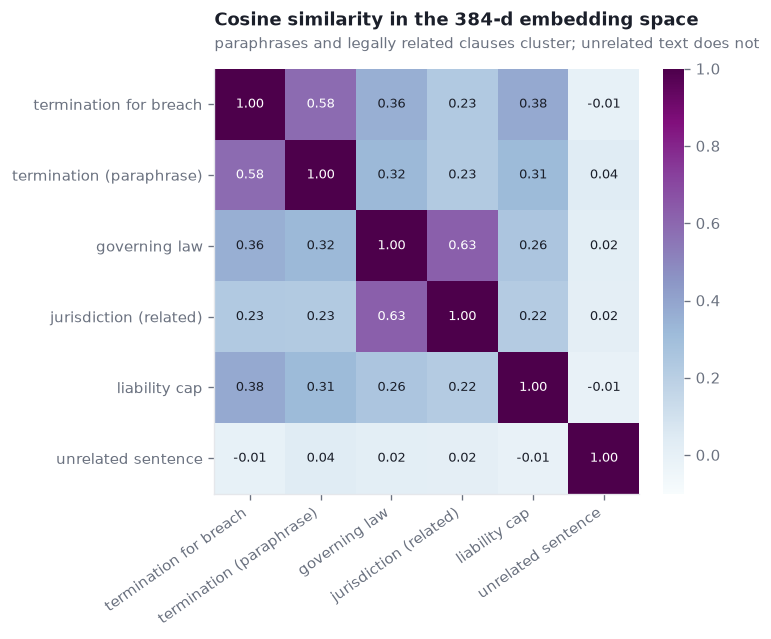

paraphrase pair            : 0.5840
governing law/jurisdiction : 0.6251
termination vs recipe      : -0.0065


In [12]:
# Does the embedding space encode legal meaning? Cosine similarity over related and unrelated sentences.
probe = {
    "termination for breach": "Either party may terminate the Agreement upon an uncured material breach.",
    "termination (paraphrase)": "The contract can be ended if one side fails to fix a serious violation.",
    "governing law": "This Agreement shall be governed by the laws of the State of New York.",
    "jurisdiction (related)": "The parties submit to the exclusive jurisdiction of the New York courts.",
    "liability cap": "Aggregate liability shall not exceed the fees paid in the preceding twelve months.",
    "unrelated sentence": "The recipe calls for two cups of flour and a pinch of sea salt.",
}
labels, texts = list(probe.keys()), list(probe.values())
E = bi_encoder.encode(texts, normalize_embeddings=True)
S = E @ E.T

fig, ax = plt.subplots(figsize=(6.6, 5.4))
im = ax.imshow(S, cmap="BuPu", vmin=-0.1, vmax=1.0)
ax.set_xticks(range(len(labels)), labels, rotation=35, ha="right")
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{S[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if S[i, j] > 0.55 else INK)
ax.set_title("Cosine similarity in the 384-d embedding space", loc="left")
ax.text(0, 1.04, "paraphrases and legally related clauses cluster; unrelated text does not",
        transform=ax.transAxes, fontsize=9, color=MUTED, va="bottom")
ax.xaxis.grid(False)
ax.yaxis.grid(False)
plt.colorbar(im, fraction=0.046, pad=0.04).outline.set_visible(False)
plt.tight_layout()
plt.show()

print(f"paraphrase pair            : {S[0, 1]:.4f}")
print(f"governing law/jurisdiction : {S[2, 3]:.4f}")
print(f"termination vs recipe      : {S[0, 5]:.4f}")

In [13]:
# Self-attention makes token representations contextual: the same word in two senses diverges.
pairs = [
    ("bank (financial)", "He deposited the settlement funds at the bank yesterday."),
    ("bank (river)", "They sat on the grassy bank of the river at dusk."),
    ("court (legal)", "The court granted the motion to dismiss the complaint."),
    ("court (tennis)", "She practised her serve on the clay court all morning."),
]
Ec = bi_encoder.encode([t for _, t in pairs], normalize_embeddings=True)

print(f"'bank'  financial vs river       : {float(Ec[0] @ Ec[1]):.4f}")
print(f"'court' legal vs tennis          : {float(Ec[2] @ Ec[3]):.4f}")
print(f"bank (financial) vs court (legal): {float(Ec[0] @ Ec[2]):.4f}")
print("\nA shared surface form does not imply a shared representation — context, via self-attention, dominates.")

'bank'  financial vs river       : 0.1695
'court' legal vs tennis          : 0.1757
bank (financial) vs court (legal): 0.2559

A shared surface form does not imply a shared representation — context, via self-attention, dominates.


<a id="5"></a>
## 5. Stage 2 — the cross-encoder re-ranker (`ms-marco-MiniLM-L-6-v2`)

The bi-encoder's speed comes from a limitation: the query and the document never see each other, so no
attention head can relate "uncured breach" in the query to "fails to remedy" in the clause. The
cross-encoder removes that limitation by concatenating the pair into a **single sequence**,

$$\texttt{[CLS]}\;\text{query}\;\texttt{[SEP]}\;\text{chunk}\;\texttt{[SEP]},$$

and running joint self-attention over it. A `Linear(384 -> 1)` head on the `[CLS]` state emits a relevance
**logit**; `CrossEncoderReranker` (`app/cross_encoder.py`) passes it through a sigmoid to obtain the
confidence score in $[0, 1]$ shown in the UI.

The cost is $O(N)$ forward passes for $N$ candidates — which is exactly why it is applied only to the
shallow pool the bi-encoder has already narrowed down, never to the corpus as a whole.

In [14]:
import math
from sentence_transformers import CrossEncoder

cross_encoder = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")
ce_cfg = cross_encoder.model.config

print("MODEL: cross-encoder/ms-marco-MiniLM-L-6-v2")
print(f"  Transformer blocks  : {ce_cfg.num_hidden_layers}")
print(f"  Hidden size         : {ce_cfg.hidden_size}")
print(f"  Attention heads     : {ce_cfg.num_attention_heads}")
print(f"  Classification head : Linear({ce_cfg.hidden_size} -> {ce_cfg.num_labels})")
print(f"  Parameters          : {sum(p.numel() for p in cross_encoder.model.parameters()):,}")

query = "Under what circumstances may a party terminate the agreement for cause?"
candidates = [
    "Either party may terminate this Agreement immediately upon written notice if the other party commits a material breach that remains uncured for thirty (30) days.",
    "Termination rights include the right of the Buyer to withdraw if regulatory approval is not obtained before the outside date.",
    "This Agreement may be terminated at any time by mutual written consent of both parties.",
    "All notices shall be sent to the addresses specified in Schedule A of this Agreement.",
    "The representations and warranties contained herein shall survive for eighteen (18) months after Closing.",
]
ce_scores = cross_encoder.predict([[query, c] for c in candidates])

pd.DataFrame({
    "logit": np.round(ce_scores, 4),
    "sigmoid": np.round([1 / (1 + math.exp(-s)) for s in ce_scores], 4),
    "passage": [c[:88] + "..." for c in candidates],
}).sort_values("logit", ascending=False).reset_index(drop=True)

MODEL: cross-encoder/ms-marco-MiniLM-L-6-v2
  Transformer blocks  : 6
  Hidden size         : 384
  Attention heads     : 12
  Classification head : Linear(384 -> 1)
  Parameters          : 22,713,601


,logit,sigmoid,passage
0,5.8836,0.9972,Either party may terminate this Agreement immediately upon written...
1,3.2825,0.9638,This Agreement may be terminated at any time by mutual written con...
2,-3.3868,0.0327,Termination rights include the right of the Buyer to withdraw if r...
3,-8.6786,0.0002,All notices shall be sent to the addresses specified in Schedule A...
4,-9.7871,0.0001,The representations and warranties contained herein shall survive ...


,bi_rank,ce_rank,rank_shift,bi_cosine,ce_logit,passage
0,2,1,1,0.6563,5.8836,Either party may terminate this Agreement immediately upon wri...
1,1,2,-1,0.6796,3.2825,This Agreement may be terminated at any time by mutual written...
2,3,3,0,0.5536,-3.3868,Termination rights include the right of the Buyer to withdraw ...
3,4,4,0,0.2715,-8.6786,All notices shall be sent to the addresses specified in Schedu...
4,5,5,0,0.2449,-9.7871,The representations and warranties contained herein shall surv...


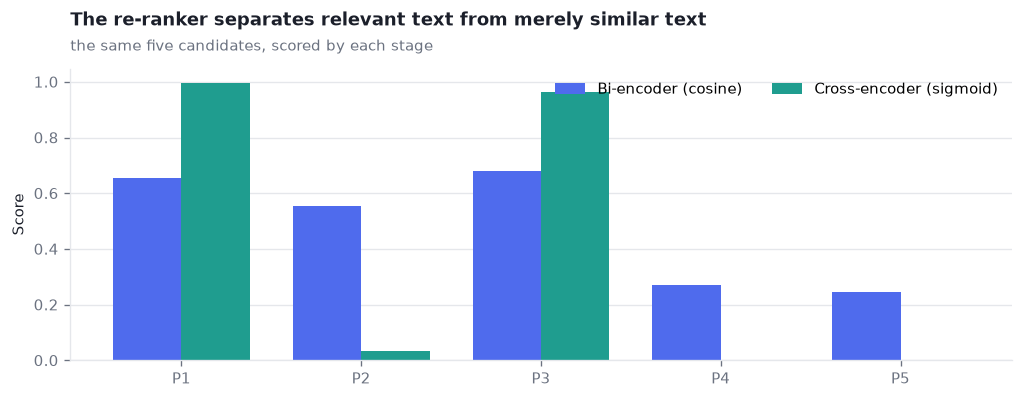

In [15]:
# Where the two stages disagree: cosine ranking vs joint-attention ranking over the same candidates.
bi_scores = (bi_encoder.encode([query], normalize_embeddings=True)
             @ bi_encoder.encode(candidates, normalize_embeddings=True).T)[0]

cmp = pd.DataFrame({
    "passage": [c[:62] + "..." for c in candidates],
    "bi_cosine": np.round(bi_scores, 4),
    "ce_logit": np.round(ce_scores, 4),
})
cmp["bi_rank"] = cmp.bi_cosine.rank(ascending=False).astype(int)
cmp["ce_rank"] = cmp.ce_logit.rank(ascending=False).astype(int)
cmp["rank_shift"] = cmp.bi_rank - cmp.ce_rank
display(cmp[["bi_rank", "ce_rank", "rank_shift", "bi_cosine", "ce_logit", "passage"]]
        .sort_values("ce_rank").reset_index(drop=True))

fig, ax = plt.subplots(figsize=(8.6, 3.4))
x = np.arange(len(candidates))
w = 0.38
ax.bar(x - w / 2, bi_scores, w, label="Bi-encoder (cosine)", color=C_STAGE1)
ax.bar(x + w / 2, [1 / (1 + math.exp(-s)) for s in ce_scores], w,
       label="Cross-encoder (sigmoid)", color=C_STAGE2)
style(ax, "The re-ranker separates relevant text from merely similar text",
      "the same five candidates, scored by each stage", "Score")
ax.set_xticks(x, [f"P{i + 1}" for i in x])
ax.legend(ncols=2)
plt.tight_layout()
plt.show()

<a id="6"></a>
## 6. The vector index (Qdrant + HNSW)

The embedded child chunks live in a local **Qdrant** collection using cosine distance over 384-d vectors,
indexed with **HNSW** (Hierarchical Navigable Small World). HNSW is a multi-layer proximity graph: sparse
upper layers allow long-range jumps into the right semantic neighbourhood, while progressively denser lower
layers refine the search locally. This turns an exhaustive $O(N)$ scan into roughly $O(\log N)$ hops.

Payload fields are stored beside each vector, which is what makes **document-scoped filtering** and
**parent expansion** possible without a second database round-trip.

> **Which index is loaded here.** The collection inspected below was built by `python/scripts/ingest.py`
> from the LegalBench-RAG gold snippets, so its payloads carry only `document_id`, `filename` and
> `source_corpus` — enough for scoped filtering and for every evaluation in Sections 9–11, but *not* the
> structural `parent_id` / `parent_content` / offset fields. Those are written by the upload path
> (`app/routes/upload.py`), which runs the parent-child pipeline from Section 3. `retrieve_chunks()`
> handles both: when parent metadata is absent it falls back to the chunk's own text, which is why the
> retrieved "parent clauses" in Sections 7–8 are labelled *Unnumbered clause*. The cell below prints the
> payload keys actually present, so this is visible rather than assumed.

In [16]:
from app.rag import get_qdrant_client

client = get_qdrant_client()
info = client.get_collection("synapse_rag")
params = info.config.params.vectors
params = params[""] if isinstance(params, dict) else params

print("COLLECTION: synapse_rag")
print(f"  Indexed vectors (child chunks) : {info.points_count:,}")
print(f"  Vector dimension               : {params.size}")
print(f"  Distance metric                : {params.distance}")
print(f"  Status                         : {info.status}")

# Sample the payload schema from one stored point (read-only scroll).
pts, _ = client.scroll(collection_name="synapse_rag", limit=1, with_payload=True, with_vectors=False)
meta = (pts[0].payload or {}).get("metadata", {})
print(f"\n  Payload metadata keys : {sorted(meta)}")
print(f"  Example filename      : {meta.get('filename')}")

COLLECTION: synapse_rag
  Indexed vectors (child chunks) : 7,662
  Vector dimension               : 384
  Distance metric                : Cosine
  Status                         : green

  Payload metadata keys : ['document_id', 'filename', 'source_corpus']
  Example filename      : ELFBEAUTY,INC_07_02_2020-EX-10.1-COOPERATION AGREEMENT.txt


In [17]:
# Corpus coverage actually present in the index (read-only full scroll over payloads).
# The filename -> document_id map built here is reused for document-scoped retrieval in Section 10.1.
files, DOCID_BY_FILE, offset = [], {}, None
while True:
    recs, offset = client.scroll(collection_name="synapse_rag", limit=2000,
                                 with_payload=True, with_vectors=False, offset=offset)
    for r in recs:
        meta = (r.payload or {}).get("metadata", {})
        fname, doc_id = meta.get("filename", ""), meta.get("document_id")
        files.append(fname)
        if fname and doc_id:
            key = fname.replace(".txt", "").lower().strip()
            for variant in (key, key.replace(" ", "_"), key.replace("_", " ")):
                DOCID_BY_FILE.setdefault(variant, doc_id)
    if offset is None:
        break

idx = pd.Series(files).value_counts()
print(f"Child chunks indexed  : {len(files):,}")
print(f"Distinct contracts    : {idx.size:,}")
print(f"Chunks per contract   : mean {idx.mean():.1f} | median {idx.median():.0f} | max {idx.max()}")
print(f"Filename lookup keys  : {len(DOCID_BY_FILE):,} (for scoped retrieval)")
print("\nMost densely indexed contracts:")
idx.head(8).to_frame("chunks")

Child chunks indexed  : 7,662
Distinct contracts    : 695
Chunks per contract   : mean 11.0 | median 10 | max 51
Filename lookup keys  : 1,855 (for scoped retrieval)

Most densely indexed contracts:


,chunks
MRSFIELDSORIGINALCOOKIESINC_01_29_1998-EX-10-FRANCHISE AGREEMENT.txt,51
RevolutionMedicinesInc_20200117_S-1_EX-10.1_11948417_EX-10.1_Development Agreement.txt,46
23andMe.txt,45
Groupon.txt,41
SoupmanInc_20150814_8-K_EX-10.1_9230148_EX-10.1_Franchise Agreement1.txt,39
MusclepharmCorp_20170208_10-KA_EX-10.38_9893581_EX-10.38_Co-Branding Agreement.txt,38
Viber Messenger.txt,38
JOINTCORP_09_19_2014-EX-10.15-FRANCHISE AGREEMENT.txt,35


<a id="7"></a>
## 7. Live two-stage retrieval

`retrieve_chunks()` (`app/rag.py`) is the production retrieval entry point. For a single query it:

1. **over-fetches** a deep candidate pool from Qdrant (`limit × 8` when re-ranking), deep enough that the
   pool still holds enough real clauses after filtering;
2. **drops heading stubs** — a chunk whose text is only a clause title (`"Section 8.2. Effect of
   Termination."`) matches heading-shaped questions better than the clause that actually answers them, so
   `drop_heading_stubs()` removes anything below `MIN_CONTEXT_WORDS` (15) unless that would leave nothing;
3. **re-ranks** the survivors with the cross-encoder and keeps the top `limit`;
4. returns every hit together with its **parent clause** and character offsets.

The two cells below run the identical query with re-ranking **off** and then **on**, against the live index.

In [18]:
from app.rag import retrieve_chunks

QUERY = "Under what circumstances can a party terminate the agreement following an uncured material breach?"

def show(chunks, title):
    print("=" * 108)
    print(f"  {title}")
    print("=" * 108)
    return pd.DataFrame([{
        "rank": i + 1,
        "score": round(c["similarity"], 4),
        "contract": (c["filename"] or "")[:40],
        "section": (c["parent_header"] or c["section_title"] or "-")[:26],
        "chunk text": " ".join(c["content"].split())[:92] + "...",
    } for i, c in enumerate(chunks)])

stage1 = retrieve_chunks(QUERY, limit=5, rerank=False)
display(show(stage1, "STAGE 1 ONLY — bi-encoder dense retrieval (cosine similarity)"))

  STAGE 1 ONLY — bi-encoder dense retrieval (cosine similarity)


,rank,score,contract,section,chunk text
0,1,0.7066,BIOPURECORP_06_30_1999-EX-10.13-AGENCY A,-,In no event will either party be liable for special or consequenti...
1,2,0.7028,TALCOTTRESOLUTIONLIFEINSURANCECO-SEPARAT,-,"This Agreement shall terminate (a) at the option of any party, upo..."
2,3,0.6929,NlsPharmaceuticsLtd_20200228_F-1_EX-10.1,-,"In addition, neither Party shall be liable for any claim under thi..."
3,4,0.6825,wayne-fueling-systems-mutual-non-disclos,-,"In any such case or upon any other termination of this Agreement, ..."
4,5,0.6638,"CARDAX,INC_08_19_2014-EX-10.1-COLLABORAT",-,"In the event of termination of this Agreement for whatever cause, ..."


In [19]:
stage2 = retrieve_chunks(QUERY, limit=5, rerank=True)
display(show(stage2, "STAGE 1 + STAGE 2 — dense retrieval followed by cross-encoder re-ranking"))

s1_files = [c["filename"] for c in stage1]
s2_files = [c["filename"] for c in stage2]
print(f"Positions whose source contract changed after re-ranking : "
      f"{sum(1 for a, b in zip(s1_files, s2_files) if a != b)}/5")
print(f"Contracts promoted into the top 5 by the re-ranker       : {len(set(s2_files) - set(s1_files))}")

  STAGE 1 + STAGE 2 — dense retrieval followed by cross-encoder re-ranking


,rank,score,contract,section,chunk text
0,1,0.9991,"HC2HOLDINGS,INC_05_14_2020-EX-10.1-COOPE",-,This Agreement will terminate upon the earlier of: (i) the conclus...
1,2,0.9987,TALCOTTRESOLUTIONLIFEINSURANCECO-SEPARAT,-,"This Agreement shall terminate (a) at the option of any party, upo..."
2,3,0.9943,GpaqAcquisitionHoldingsInc_20200123_S-4A,-,Each of the HOF Entities or Constellation may terminate this Agree...
3,4,0.9848,CYBERIANOUTPOSTINC_07_09_1998-EX-10.13-P,-,"The term of this Agreement (the ""Term"") will begin on February 1, ..."
4,5,0.9792,PhoenixNewMediaLtd_20110421_F-1_EX-10.17,-,In the event that 8.2.1 one Party is in breach of its obligations ...


Positions whose source contract changed after re-ranking : 4/5
Contracts promoted into the top 5 by the re-ranker       : 4


In [20]:
# Latency of each stage, measured against the live index (median of three runs).
import time

def timed(fn, n=3):
    ts = []
    for _ in range(n):
        t0 = time.perf_counter()
        fn()
        ts.append((time.perf_counter() - t0) * 1000)
    return float(np.median(ts))

probe_q = "What is the governing law and chosen forum for disputes under this agreement?"
t_embed = timed(lambda: bi_encoder.encode([probe_q], normalize_embeddings=True))
t_stage1 = timed(lambda: retrieve_chunks(probe_q, limit=5, rerank=False))
t_stage2 = timed(lambda: retrieve_chunks(probe_q, limit=5, rerank=True))

display(pd.DataFrame({
    "step": ["Query embedding (bi-encoder)", "Stage 1: embed + HNSW search", "Stage 1 + Stage 2 (re-ranked)"],
    "median_ms": [round(t_embed, 1), round(t_stage1, 1), round(t_stage2, 1)],
}))
print(f"Re-ranking overhead: +{t_stage2 - t_stage1:.0f} ms over Stage 1 alone "
      f"({(t_stage2 / t_stage1 - 1) * 100:.0f}% slower) for a candidate pool of ~{max(5 * 8, 60)} chunks.")

,step,median_ms
0,Query embedding (bi-encoder),5.8
1,Stage 1: embed + HNSW search,26.4
2,Stage 1 + Stage 2 (re-ranked),647.5


Re-ranking overhead: +621 ms over Stage 1 alone (2352% slower) for a candidate pool of ~60 chunks.


<a id="8"></a>
## 8. Parent expansion, prompt construction and grounded generation

Retrieval returns *children*; the LLM must read *clauses*. `format_context()` walks the ranked children,
expands each to its parent clause, **de-duplicates by `(document_id, parent_id)`** so a clause whose three
children all matched is still injected once, and stops at `MAX_PARENT_CLAUSES` (default 6) to bound the
prompt. Each block is labelled with its document, section heading, relevance score and character span —
and that label is what the UI turns into a verifiable citation.

The system prompt then enforces strict grounding: answer only from the excerpts, quote operative language
verbatim, cite section numbers, and refuse explicitly when the context does not contain the answer.

As noted in Section 6, the loaded benchmark index carries no structural metadata, so parent expansion here
degrades gracefully to the retrieved chunk itself and the section label reads *Unnumbered clause*. The
de-duplication and the clause cap still apply, and both are visible in the cell below (five children
collapse to three prompt blocks).

In [21]:
from app.rag import format_context, SYSTEM_PROMPT

context = format_context(stage2, max_parent_clauses=3)
print(f"Children retrieved: {len(stage2)}  ->  unique parent clauses in prompt: "
      f"{context.count('--- [Parent Clause')}")
print(f"Context length: {len(context):,} characters\n")
print(context[:2600] + ("\n\n... [truncated for display]" if len(context) > 2600 else ""))

Children retrieved: 5  ->  unique parent clauses in prompt: 3
Context length: 1,382 characters

--- [Parent Clause 1 | Document: HC2HOLDINGS,INC_05_14_2020-EX-10.1-COOPERATION AGREEMENT.txt | Unnumbered clause | Relevance Score: 0.999] ---
This Agreement will terminate upon the earlier of: (i) the conclusion of the Standstill Period or (ii) delivery of written notice by one Party to the other Party of a material breach of this Agreement by the breaching Party that is uncured after ten (10) calendar days of notice of such breach.

--- [Parent Clause 2 | Document: TALCOTTRESOLUTIONLIFEINSURANCECO-SEPARATEACCOUNTTWELVE_04_30_2020-EX-99.8(L)-SERVICE AGREEMENT.txt | Unnumbered clause | Relevance Score: 0.999] ---
This Agreement shall terminate (a) at the option of any party, upon 90 days' advance written notice to the other parties hereto; or (b) in the event of a material breach that has not been cured within ten days following a written notice of breach to the breaching party.

--- [Paren

In [22]:
print("SYSTEM PROMPT (app/rag.py)")
print("=" * 100)
print(SYSTEM_PROMPT)

SYSTEM PROMPT (app/rag.py)
You are Synapse RAG, an expert legal contract analyst specializing in corporate M&A agreements, commercial contracts, and regulatory filings.

Your primary directive is to provide rigorous, accurate, and completely grounded legal analysis based EXCLUSIVELY on the provided contract excerpts.

CORE OPERATING PRINCIPLES:
1. STRICT FACTUAL GROUNDING:
   - Base your answer ONLY on the provided Context excerpts.
   - Do NOT assume, extrapolate, or introduce outside legal terms or clauses not present in the excerpts.
   - If the Context does not contain the necessary information to answer the question, state clearly: "I cannot answer this question based on the provided contract excerpts."

2. PRECISE LEGAL CITATION & QUOTATION:
   - Directly cite the specific section numbers, article headings, and document names whenever available (e.g., "Under Section 6.2(a) of [Document]...").
   - Quote operative contractual language verbatim using quotation marks for key definit

In [23]:
# End-to-end generation against the live Groq endpoint, grounded in the retrieved clauses.
from langchain_core.messages import HumanMessage, SystemMessage
from app.rag import get_llm

try:
    llm = get_llm(streaming=False, temperature=0.2, max_tokens=900)
    answer = llm.invoke([
        SystemMessage(content=SYSTEM_PROMPT),
        HumanMessage(content=f"Context:\n{format_context(stage2)}\n\nQuestion: {QUERY}"),
    ]).content
    print("QUESTION:", QUERY)
    print("=" * 100)
    print(answer)
except Exception as exc:
    print(f"[Generation skipped — the LLM endpoint is unavailable: {exc}]")
    print("Retrieval above is unaffected; only this cell requires network access.")

QUESTION: Under what circumstances can a party terminate the agreement following an uncured material breach?
**Answer (direct):**  
A party may terminate the agreement if the other party commits a material breach that remains uncured after the specified cure period following written notice of breach.  

**Detailed analysis (based on the provided excerpts):**

| Document | Relevant clause | Termination trigger | Notice & cure period | Additional conditions |
|----------|-----------------|---------------------|----------------------|-----------------------|
| **HC2HOLDINGS,INC_05_14_2020-EX-10.1-COOPERATION AGREEMENT** | Unnumbered clause | “delivery of written notice by one Party to the other Party of a material breach … that is uncured after ten (10) calendar days of notice” | 10 calendar days | Termination occurs *upon* the earlier of the Standstill Period conclusion or the uncured breach notice. |
| **TALCOTTRESOLUTIONLIFEINSURANCECO-SEPARATEACCOUNTTWELVE_04_30_2020-EX-99.8(L)-SERVIC

In [24]:
# The refusal path: a question the corpus cannot answer must not be answered anyway.
OFF_TOPIC = "What is the boiling point of water at the summit of Mount Everest?"

try:
    off_chunks = retrieve_chunks(OFF_TOPIC, limit=4, rerank=True)
    llm = get_llm(streaming=False, temperature=0.0, max_tokens=300)
    refusal = llm.invoke([
        SystemMessage(content=SYSTEM_PROMPT),
        HumanMessage(content=f"Context:\n{format_context(off_chunks)}\n\nQuestion: {OFF_TOPIC}"),
    ]).content
    print("QUESTION:", OFF_TOPIC)
    print("Retrieved (irrelevant) contracts:", [c["filename"][:34] for c in off_chunks[:3]])
    print("=" * 100)
    print(refusal)
except Exception as exc:
    print(f"[Generation skipped — the LLM endpoint is unavailable: {exc}]")

QUESTION: What is the boiling point of water at the summit of Mount Everest?
Retrieved (irrelevant) contracts: ['TickTick_ To Do List with Reminder', 'ENERGYXXILTD_05_08_2015-EX-10.13-T', 'ENTERPRISEPRODUCTSPARTNERSLP_07_08']
I cannot answer this question based on the provided contract excerpts.


<a id="9"></a>
## 9. Results I — retrieval quality and re-ranking lift

This is the project's **primary quantitative result**, and the most reliable one, because it needs no LLM:
LegalBench-RAG gives the gold character span, so retrieval can be scored directly against it.

`scripts/evaluate_retrieval.py` samples 200 queries (`seed=0`), retrieves `k=20` chunks per query against
the live index, and scores two configurations — bi-encoder alone, and bi-encoder followed by cross-encoder
re-ranking:

* **Document Recall@k** — the correct contract appears in the top $k$.
* **Snippet Recall@k** — a retrieved chunk actually overlaps the gold answer span.
* **MRR** — mean reciprocal rank of the first correct hit, $\frac{1}{|Q|}\sum_q \frac{1}{\text{rank}_q}$;
  unlike recall, it rewards putting the right passage *first*.

```
python scripts/evaluate_retrieval.py --limit 200 --seed 0 --k 20
```

The cells below load `results/retrieval_metrics.json` as written by that run.

In [25]:
with open(RESULTS_DIR / "retrieval_metrics.json", encoding="utf-8") as f:
    retrieval = json.load(f)

cfg_names = ["bi-encoder only", "bi-encoder + cross-encoder"]
m = {name: retrieval[name]["metrics"] for name in cfg_names}

table = pd.DataFrame({
    "Metric": ["Doc Recall@1", "Doc Recall@5", "Doc Recall@20", "Doc MRR",
               "Snippet Recall@1", "Snippet Recall@5", "Snippet Recall@20", "Snippet MRR"],
    "Stage 1 only": [m[cfg_names[0]][k] for k in
                     ["doc_recall_at_1", "doc_recall_at_5", "doc_recall_at_20", "doc_mrr",
                      "snip_recall_at_1", "snip_recall_at_5", "snip_recall_at_20", "snip_mrr"]],
    "Stage 1 + 2 (re-ranked)": [m[cfg_names[1]][k] for k in
                     ["doc_recall_at_1", "doc_recall_at_5", "doc_recall_at_20", "doc_mrr",
                      "snip_recall_at_1", "snip_recall_at_5", "snip_recall_at_20", "snip_mrr"]],
})
table["Δ (lift)"] = (table["Stage 1 + 2 (re-ranked)"] - table["Stage 1 only"]).round(3)

print(f"Queries: {m[cfg_names[0]]['n']} | k = {m[cfg_names[0]]['k']} | sampling seed = {m[cfg_names[0]]['seed']}")
print("Recall values are percentages; MRR is a 0-1 score.\n")
display(table)

print(f"Headline: cross-encoder re-ranking lifts Document Recall@1 from "
      f"{m[cfg_names[0]]['doc_recall_at_1']}% to {m[cfg_names[1]]['doc_recall_at_1']}% "
      f"(+{m[cfg_names[1]]['doc_recall_at_1'] - m[cfg_names[0]]['doc_recall_at_1']:.1f} points, "
      f"a {(m[cfg_names[1]]['doc_recall_at_1'] / m[cfg_names[0]]['doc_recall_at_1'] - 1) * 100:.0f}% relative gain), "
      f"and Document MRR from {m[cfg_names[0]]['doc_mrr']:.3f} to {m[cfg_names[1]]['doc_mrr']:.3f}.")

Queries: 200 | k = 20 | sampling seed = 0
Recall values are percentages; MRR is a 0-1 score.



,Metric,Stage 1 only,Stage 1 + 2 (re-ranked),Δ (lift)
0,Doc Recall@1,31.500,45.000,13.500
1,Doc Recall@5,44.500,50.000,5.500
2,Doc Recall@20,55.500,59.000,3.500
3,Doc MRR,0.374,0.477,0.103
4,Snippet Recall@1,13.000,12.000,-1.000
5,Snippet Recall@5,23.500,25.000,1.500
6,Snippet Recall@20,35.000,37.000,2.000
7,Snippet MRR,0.182,0.178,-0.004


Headline: cross-encoder re-ranking lifts Document Recall@1 from 31.5% to 45.0% (+13.5 points, a 43% relative gain), and Document MRR from 0.374 to 0.477.


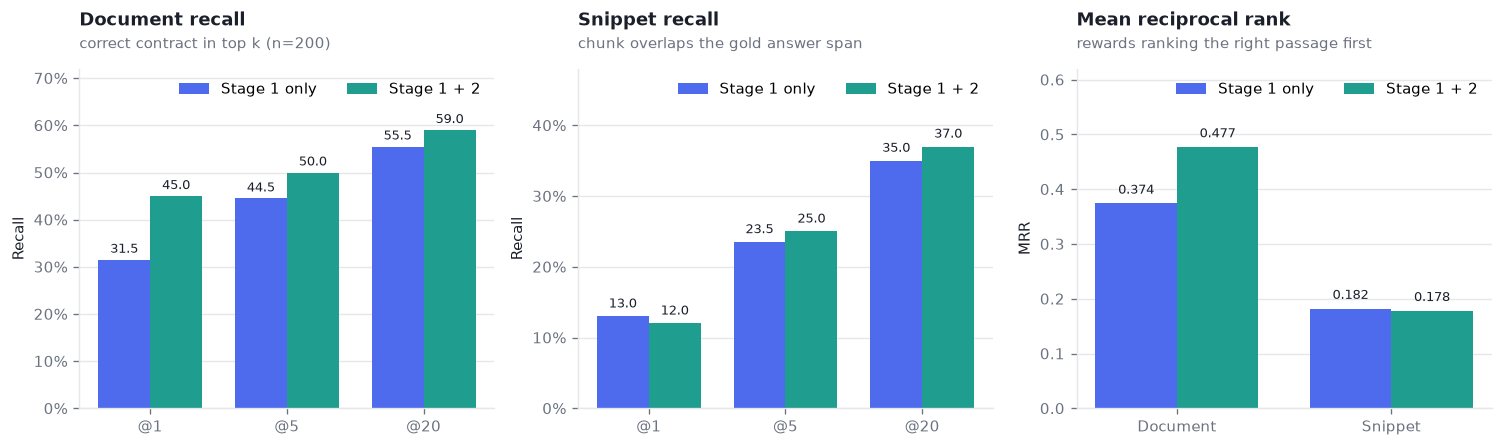

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.8))
x = np.arange(3)
w = 0.38
ks = ["@1", "@5", "@20"]

# Document-level recall
d1 = [m[cfg_names[0]][f"doc_recall_at_{k}"] for k in (1, 5, 20)]
d2 = [m[cfg_names[1]][f"doc_recall_at_{k}"] for k in (1, 5, 20)]
b1 = axes[0].bar(x - w / 2, d1, w, label="Stage 1 only", color=C_STAGE1)
b2 = axes[0].bar(x + w / 2, d2, w, label="Stage 1 + 2", color=C_STAGE2)
style(axes[0], "Document recall", "correct contract in top k (n=200)", "Recall", pct=True)
axes[0].set_xticks(x, ks)
axes[0].set_ylim(0, 72)
label_bars(axes[0], b1)
label_bars(axes[0], b2)
axes[0].legend(ncols=2)

# Snippet-level recall
s1 = [m[cfg_names[0]][f"snip_recall_at_{k}"] for k in (1, 5, 20)]
s2 = [m[cfg_names[1]][f"snip_recall_at_{k}"] for k in (1, 5, 20)]
b3 = axes[1].bar(x - w / 2, s1, w, label="Stage 1 only", color=C_STAGE1)
b4 = axes[1].bar(x + w / 2, s2, w, label="Stage 1 + 2", color=C_STAGE2)
style(axes[1], "Snippet recall", "chunk overlaps the gold answer span", "Recall", pct=True)
axes[1].set_xticks(x, ks)
axes[1].set_ylim(0, 48)
label_bars(axes[1], b3)
label_bars(axes[1], b4)
axes[1].legend(ncols=2)

# MRR
mx = np.arange(2)
b5 = axes[2].bar(mx - w / 2, [m[cfg_names[0]]["doc_mrr"], m[cfg_names[0]]["snip_mrr"]], w,
                 label="Stage 1 only", color=C_STAGE1)
b6 = axes[2].bar(mx + w / 2, [m[cfg_names[1]]["doc_mrr"], m[cfg_names[1]]["snip_mrr"]], w,
                 label="Stage 1 + 2", color=C_STAGE2)
style(axes[2], "Mean reciprocal rank", "rewards ranking the right passage first", "MRR")
axes[2].set_xticks(mx, ["Document", "Snippet"])
axes[2].set_ylim(0, 0.62)
label_bars(axes[2], b5, "{:.3f}", dy=0.012)
label_bars(axes[2], b6, "{:.3f}", dy=0.012)
axes[2].legend(ncols=2)

plt.tight_layout()
plt.show()

In [27]:
# Where the lift comes from: per-query rank movement, broken down by sub-corpus.
pq1 = pd.DataFrame(retrieval[cfg_names[0]]["per_query"])
pq2 = pd.DataFrame(retrieval[cfg_names[1]]["per_query"])
for df in (pq1, pq2):
    df["corpus"] = df.id.str.split("_").str[0]

merged = pq1.merge(pq2, on="id", suffixes=("_s1", "_s2"))
merged["corpus"] = merged.id.str.split("_").str[0]

by_corpus = merged.groupby("corpus").agg(
    queries=("id", "size"),
    doc_r1_stage1=("doc_recall_1_s1", lambda s: 100 * s.mean()),
    doc_r1_stage2=("doc_recall_1_s2", lambda s: 100 * s.mean()),
    doc_mrr_stage1=("doc_mrr_s1", "mean"),
    doc_mrr_stage2=("doc_mrr_s2", "mean"),
).round(3)
by_corpus["r1_lift"] = (by_corpus.doc_r1_stage2 - by_corpus.doc_r1_stage1).round(1)
display(by_corpus.sort_values("queries", ascending=False))

promoted = int(((merged.doc_recall_1_s2 == 1) & (merged.doc_recall_1_s1 == 0)).sum())
demoted = int(((merged.doc_recall_1_s2 == 0) & (merged.doc_recall_1_s1 == 1)).sum())
print(f"Queries where re-ranking promoted the correct contract to rank 1 : {promoted}")
print(f"Queries where re-ranking displaced a previously correct rank 1   : {demoted}")
print(f"Net change: {promoted - demoted:+d} queries out of {len(merged)}")

,queries,doc_r1_stage1,doc_r1_stage2,doc_mrr_stage1,doc_mrr_stage2,r1_lift
corpus,,,,,,
cuad,115,45.217,70.435,0.541,0.737,25.2
maud,51,7.843,7.843,0.096,0.091,0.0
contractnli,31,12.903,9.677,0.151,0.126,-3.2
privacy,3,100.000,66.667,1.000,0.708,-33.3


Queries where re-ranking promoted the correct contract to rank 1 : 33
Queries where re-ranking displaced a previously correct rank 1   : 6
Net change: +27 queries out of 200


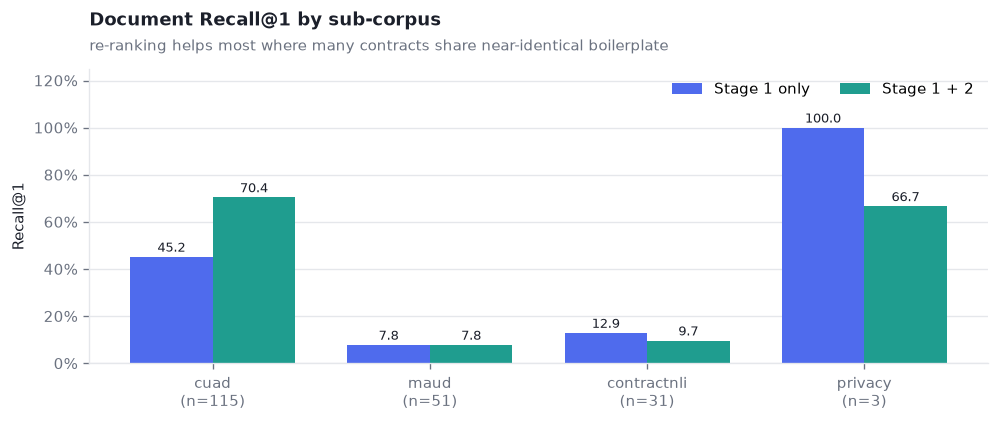

In [28]:
fig, ax = plt.subplots(figsize=(8.4, 3.6))
order = by_corpus.sort_values("queries", ascending=False)
x = np.arange(len(order))
w = 0.38
b1 = ax.bar(x - w / 2, order.doc_r1_stage1, w, label="Stage 1 only", color=C_STAGE1)
b2 = ax.bar(x + w / 2, order.doc_r1_stage2, w, label="Stage 1 + 2", color=C_STAGE2)
style(ax, "Document Recall@1 by sub-corpus",
      "re-ranking helps most where many contracts share near-identical boilerplate", "Recall@1", pct=True)
ax.set_xticks(x, [f"{c}\n(n={int(n)})" for c, n in zip(order.index, order.queries)])
ax.set_ylim(0, max(order.doc_r1_stage2.max(), order.doc_r1_stage1.max()) * 1.25)
label_bars(ax, b1)
label_bars(ax, b2)
ax.legend(ncols=2)
plt.tight_layout()
plt.show()

### Reading these numbers

**Re-ranking works, and it works where theory predicts it should.** Document Recall@1 rises
**31.5% → 45.0%** and Document MRR **0.374 → 0.477**: the cross-encoder's joint attention is far better at
telling *which* of twenty superficially similar M&A agreements the question is actually about, because the
bi-encoder's independent encodings cannot compare query terms against document terms.

**Snippet-level recall barely moves (13.0% → 12.0% at k=1, 35% → 37% at k=20).** This is an honest
limitation, and the cause is the index rather than the models: the LegalBench ingestion
(`python/scripts/ingest.py`) stores gold *snippets* as flat vectors, so many corpus chunks are short,
boilerplate-heavy and nearly interchangeable across contracts. Re-ranking can reorder such a pool, but it
cannot recover exact-span precision that chunking never encoded. The structural parent-child pipeline from
Section 3 is what addresses this, and it is applied to uploaded contracts; re-ingesting the whole benchmark
corpus through it is the main outstanding piece of work.

**Absolute recall should be read against the task.** A single query must find one specific clause among
7,662 chunks drawn from 695 contracts whose language is deliberately standardised — Recall@20 of 59% at the
document level is a reasonable baseline for an unsupervised, general-purpose 22M-parameter encoder with no
legal-domain fine-tuning.

<a id="10"></a>
## 10. Results II — end-to-end faithfulness ablation

Retrieval metrics say nothing about whether the *generated answer* is grounded.
`scripts/evaluate_faithfulness.py` therefore runs a 2×2 ablation over 50 MAUD queries —
**document-scoped vs unscoped** × **re-ranking off vs on** — and scores each generated answer with an
**LLM-as-a-judge**: accuracy against the gold answer, faithfulness to the retrieved context, and
hallucination rate.

```
python scripts/evaluate_faithfulness.py --limit 50 [--scoped] [--rerank]
```

> **Validity caveat — read before citing these numbers.** The judge was configured as
> `llama-3.1-8b-instant`, which has since been **decommissioned on Groq**. Every judge call in these saved
> runs returned HTTP 404, and `parse_judge_json()` falls back to a string heuristic that resolves an error
> string to a score of **1**. The `accuracy`, `faithfulness` and `hallucination_rate` figures in the saved
> files are therefore **artifacts, not measurements**. The cell below quantifies the damage per run, and
> Section 10.1 re-measures a small sample with a judge model that works.
>
> Two further caveats apply even to the non-judge columns: in the **scoped** runs, hit rate is
> `len(chunks) > 0` — guaranteed by the document filter, hence trivially 100% — so only the **unscoped**
> hit rate is informative; and a majority of unscoped answers came back empty, which inflates `accuracy`
> further, since an empty answer is not detected as a refusal.

In [29]:
configs = {
    "scoped, no re-rank": "faithfulness_scoped_norerank.json",
    "scoped + re-rank": "faithfulness_scoped_rerank.json",
    "unscoped, no re-rank": "faithfulness_unscoped_norerank.json",
    "unscoped + re-rank": "faithfulness_unscoped_rerank.json",
}

rows = []
for name, fname in configs.items():
    with open(RESULTS_DIR / fname, encoding="utf-8") as f:
        payload = json.load(f)
    res = payload["results"]
    judge_failed = sum(1 for r in res if str(r.get("faithfulness_reason", "")).startswith("Error"))
    empty = sum(1 for r in res if not str(r.get("generated_answer", "")).strip())
    refusals = sum(1 for r in res
                   if "cannot answer this question based on the provided"
                   in str(r.get("generated_answer", "")).lower())
    rows.append({
        "configuration": name,
        "n": len(res),
        "hit_rate_%": payload["metrics"]["hit_rate"],
        "hit_rate_valid": "no (filter-guaranteed)" if name.startswith("scoped") else "yes",
        "reported_accuracy_%": payload["metrics"]["accuracy"],
        "reported_faithfulness_%": payload["metrics"]["faithfulness"],
        "judge_calls_failed": f"{judge_failed}/{len(res)}",
        "empty_answers": empty,
        "explicit_refusals": refusals,
    })

ablation = pd.DataFrame(rows)
display(ablation)
print("Only `hit_rate_%` for the two unscoped rows is a valid measurement; every judge-derived column is "
      "invalidated by the 404s counted in `judge_calls_failed`.")

,configuration,n,hit_rate_%,hit_rate_valid,reported_accuracy_%,reported_faithfulness_%,judge_calls_failed,empty_answers,explicit_refusals
0,"scoped, no re-rank",50,100.0,no (filter-guaranteed),58.00,98.0,0/50,2,15
1,scoped + re-rank,50,100.0,no (filter-guaranteed),26.92,100.0,0/50,3,15
2,"unscoped, no re-rank",50,30.0,yes,4.55,100.0,0/50,0,41
3,unscoped + re-rank,50,26.0,yes,0.00,100.0,0/50,27,18


Only `hit_rate_%` for the two unscoped rows is a valid measurement; every judge-derived column is invalidated by the 404s counted in `judge_calls_failed`.


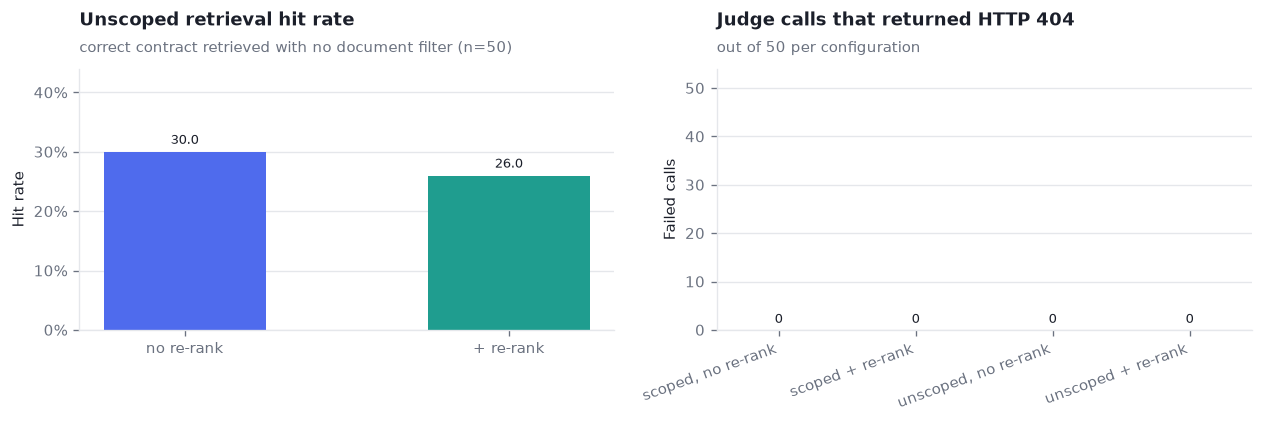

Unscoped hit rate is 30% without re-ranking and 26% with it. Re-ranking a pool of 8 chunks drawn from 695 contracts cannot repair a candidate pool that never contained the right contract — which is precisely why the product scopes queries to a selected document, and why fan-out (Section 11) searches per document rather than globally.


In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.6, 3.6))

uns = ablation[ablation.configuration.str.startswith("unscoped")]
bars = ax1.bar(["no re-rank", "+ re-rank"], uns["hit_rate_%"], color=[C_STAGE1, C_STAGE2], width=0.5)
style(ax1, "Unscoped retrieval hit rate", "correct contract retrieved with no document filter (n=50)",
      "Hit rate", pct=True)
ax1.set_ylim(0, 44)
label_bars(ax1, bars)

bars2 = ax2.bar(ablation.configuration, [int(s.split("/")[0]) for s in ablation.judge_calls_failed],
                color=C_WARN, width=0.55)
style(ax2, "Judge calls that returned HTTP 404", "out of 50 per configuration", "Failed calls")
ax2.set_xticks(range(len(ablation)), ablation.configuration, rotation=20, ha="right")
ax2.set_ylim(0, 54)
label_bars(ax2, bars2, "{:.0f}")

plt.tight_layout()
plt.show()

print("Unscoped hit rate is 30% without re-ranking and 26% with it. Re-ranking a pool of 8 chunks drawn "
      "from 695 contracts cannot repair a candidate pool that never contained the right contract — which "
      "is precisely why the product scopes queries to a selected document, and why fan-out (Section 11) "
      "searches per document rather than globally.")

### 10.1 Re-measuring faithfulness live, with a corrected judge

Rather than cite invalid numbers, the cell below re-runs the end-to-end loop on a sample of MAUD queries
(configured by `SAMPLE_N` below, default 20) using the **currently configured** Groq model as both
generator and judge. It runs the strongest configuration — **document-scoped retrieval with re-ranking** —
resolving each query's `document_id` through the map built in Section 6, exactly as the evaluation script does.

Key evaluation safeguards and metrics:

1. **Judge error handling** — if the judge LLM call fails or returns an unparseable response, the score is
   recorded as `None` (with diagnostic logging) and excluded from reported averages via `.dropna()`.
   Ambiguous fallback regex matching is avoided so unparseable replies are not coerced to 0 or 1.
2. **Faithfulness (affirmative answers)** — substantive answers are compared against retrieved contract excerpts
   to ensure every factual claim is grounded without external fabrication. Hallucination rate is reported
   strictly as `1 - faithfulness` on these affirmative answers.
3. **Refusal appropriateness (refusals)** — refusals are evaluated separately in their own `refusal_appropriate`
   metric rather than automatically awarded a perfect score. A refusal scores 1 only when the judge confirms
   that the context genuinely lacked the required information.
4. **Generation failures excluded** — an empty generation is a missing measurement, not a wrong
   answer, and judging one would score it vacuously faithful. Such items are reported on their own
   line and excluded from every rate, as `scripts/evaluate_faithfulness.py` does.
5. **Judge token budget** — the `gpt-oss` judges spend part of their completion budget on reasoning
   tokens before emitting the JSON verdict, so too small a ceiling returns empty content. The judge
   runs with `JUDGE_MAX_TOKENS` headroom and reports `finish_reason` when a reply is empty.
6. **Judges see the full context** -- the grounding and refusal judges receive the same context
   the generator did, not a truncated prefix. Under document-scoped retrieval that context runs
   7-10k characters, so a 4000-character cap hid later clauses from the judge and scored
   correctly-grounded claims as hallucinations.
7. **Retry and truncation detection** — judge calls use exponential backoff on rate limits, and the summary
   explicitly indicates if a run was truncated before evaluating the full `SAMPLE_N` queries.

In [31]:
import time
import re as _re
from langchain_core.messages import HumanMessage, SystemMessage
from app.rag import get_llm, retrieve_chunks, format_context, SYSTEM_PROMPT

SAMPLE_N = 20
JUDGE_MAX_TOKENS = 1024
maud = [item for item in qa_pairs if item["id"].startswith("maud_")][:SAMPLE_N]

def call_llm_with_retry(llm, messages, retries=5):
    """Invoke an LLM with exponential backoff on rate limits (429 / token budget).

    Returns (text, finish_reason). text starts with "Error:" on a hard failure and is
    empty when the model emitted no visible content -- finish_reason then says why.
    """
    last_err = "retries exhausted"
    for attempt in range(retries):
        try:
            res = llm.invoke(messages)
            text = res.content if hasattr(res, "content") else str(res)
            meta = getattr(res, "response_metadata", None) or {}
            return text, meta.get("finish_reason", "unknown")
        except Exception as e:
            last_err = str(e)
            err_str = last_err.lower()
            if "429" in err_str or "rate limit" in err_str:
                time.sleep(3 * (attempt + 1))
            elif attempt == retries - 1:
                return f"Error: {e}", "exception"
            else:
                time.sleep(1.5)
    return f"Error: {last_err}", "exception"

def judge(llm, prompt):
    """Ask the judge for strict 1/0 JSON; return None when the call or parse fails."""
    raw, finish = call_llm_with_retry(llm, [HumanMessage(content=prompt)])
    if raw.startswith("Error:"):
        print(f"    [judge call failed: {raw}]")
        return None  # API error / rate limit -> exclude from average
    if not raw.strip():
        # gpt-oss judges spend part of the completion budget on reasoning tokens before
        # emitting the verdict; too small a ceiling returns empty content with
        # finish_reason="length". JUDGE_MAX_TOKENS below keeps the verdict inside budget.
        print(f"    [judge returned no visible content (finish_reason={finish}) "
              "-- raise JUDGE_MAX_TOKENS if this recurs]")
        return None

    match = _re.search(r'"score"\s*:\s*([01])', raw)
    if match:
        return int(match.group(1))
    bare = _re.fullmatch(r"\s*([01])\s*", raw.strip())
    if bare:
        return int(bare.group(1))

    # Unparseable response -> exclude from average (do not use ambiguous \b[01]\b regex)
    print(f"    [judge returned unparseable response: {raw[:120]!r}]")
    return None

def fmt_pct(series):
    """Format series mean as percentage, or 'n/a' if empty/NaN."""
    if series is None or len(series) == 0 or pd.isna(series.mean()):
        return "n/a"
    return f"{100 * series.mean():.1f}%"

live_rows = []
truncated = False
abort_reason = None

try:
    # Generation uses the app's own default ceiling (app.rag.get_llm -> 2048), as
    # evaluate_faithfulness.py does: a smaller override truncated reasoning-model answers
    # to empty strings. The judge needs room for reasoning tokens plus the JSON verdict.
    # The judges receive the context and answer in full. Capping the context at 4000
    # characters showed the judge only part of what the generator saw -- scoped retrieval
    # yields 7-10k characters here -- so claims grounded in a later clause were scored as
    # hallucinations. evaluate_faithfulness.py passes its context whole for the same reason.
    # Ground truth stays capped: LegalBench answers reach ~10k characters and are reference
    # text, not something the generated answer is matched against clause by clause.
    gen_llm = get_llm(streaming=False, temperature=0.1)
    judge_llm = get_llm(streaming=False, temperature=0.0, max_tokens=JUDGE_MAX_TOKENS)

    for item in maud:
        meta = item["metadata"]
        q, gold = meta["query"], meta["answer"]
        expected = meta["corpus_file"].split("/")[-1].replace(".txt", "").lower().strip()

        # Scope search to the expected contract, as evaluate_faithfulness.py does with --scoped.
        target_doc_id = (DOCID_BY_FILE.get(expected)
                         or DOCID_BY_FILE.get(expected.replace(" ", "_"))
                         or DOCID_BY_FILE.get(expected.replace("_", " ")))
        chunks = retrieve_chunks(q, document_id=target_doc_id, limit=8, rerank=True)
        hit = any(expected in (c["filename"] or "").lower().replace(".txt", "")
                  or (c["filename"] or "").lower().replace(".txt", "") in expected for c in chunks)
        ctx = format_context(chunks)

        answer = gen_llm.invoke([
            SystemMessage(content=f"{SYSTEM_PROMPT}\n\n=== CONTEXT ===\n\n{ctx}"),
            HumanMessage(content=f"Answer strictly from the excerpts, quoting the operative clause.\n\nQUERY: {q}"),
        ]).content
        # A generation that produced no text is a missing measurement, not a wrong answer:
        # judging it would score an empty string (and be scored vacuously faithful), so the
        # item is left unscored and counted separately -- as evaluate_faithfulness.py does.
        gen_failed = not answer.strip()
        refused = (not gen_failed
                   and "cannot answer this question based on the provided" in answer.lower())

        # Accuracy: 0 for refusals; judged score (or None on failure) for substantive answers
        # Faithfulness: claims grounded in context (affirmative answers only)
        # Refusal appropriateness: judged only on refusals (did context genuinely lack info?)
        if gen_failed:
            acc = faith = ref_app = None
        elif refused:
            acc = 0
            faith = None
            ref_app = judge(judge_llm,
                "You are a strict faithfulness judge for a RAG system. "
                "The model REFUSED to answer the query. "
                "Is that refusal appropriate given the CONTEXT — i.e., does the context genuinely lack "
                "enough information to answer the query? "
                'Reply with JSON only: {"score": 1} if the refusal is appropriate, {"score": 0} if the '
                "context actually contains a relevant answer.\n\n"
                f"QUERY:\n{q[:500]}\n\nCONTEXT:\n{ctx}")
        else:
            acc = judge(judge_llm,
                "You are a strict legal evaluation judge. Does the ANSWER convey the same substantive legal "
                'content as the GROUND TRUTH? Reply with JSON only: {"score": 1} or {"score": 0}.\n\n'
                f"GROUND TRUTH:\n{gold[:1500]}\n\nANSWER:\n{answer}")
            faith = judge(judge_llm,
                "You are a strict faithfulness judge for a RAG system. Is every factual claim in the ANSWER "
                "supported by the CONTEXT, with no outside knowledge introduced? Reply with JSON only: "
                '{"score": 1} or {"score": 0}.\n\n'
                f"CONTEXT:\n{ctx}\n\nANSWER:\n{answer}")
            ref_app = None

        live_rows.append({
            "id": item["id"],
            "generation_failed": gen_failed,
            "scoped": target_doc_id is not None,
            "retrieval_hit": hit,
            "refused": refused,
            "accuracy": acc,
            "faithful": faith,
            "refusal_appropriate": ref_app,
            "answer_chars": len(answer),
        })
        if gen_failed:
            print(f"  {item['id']:<12} scoped={'Y' if target_doc_id else 'N'} "
                  f"hit={'Y' if hit else 'N'} GENERATION FAILED (empty answer, not judged)")
        else:
            print(f"  {item['id']:<12} scoped={'Y' if target_doc_id else 'N'} "
                  f"hit={'Y' if hit else 'N'} refused={'Y' if refused else 'N'} "
                  f"acc={acc} faith={faith} ref_app={ref_app}")
        time.sleep(1.0)
except Exception as exc:
    truncated = True
    abort_reason = str(exc)
    print(f"[Live evaluation stopped early — {exc}]")

if live_rows:
    live = pd.DataFrame(live_rows)
    n = len(live)
    is_truncated = truncated or (n < len(maud))
    status_str = f"TRUNCATED at {n}/{SAMPLE_N} items ({abort_reason})" if is_truncated else f"complete ({n}/{SAMPLE_N} items)"

    scored_acc = live.accuracy.dropna()
    scored_faith = live.faithful.dropna()
    scored_ref_app = live.refusal_appropriate.dropna()
    # Each metric has its own population: accuracy covers every judged item, faithfulness
    # only affirmative answers, appropriateness only refusals. Generation failures sit
    # outside all three, so they are reported separately rather than counted as unscored.
    n_gen_failed = int(live.generation_failed.sum())
    n_refusals = int(live.refused.sum())
    n_judged = n - n_gen_failed
    n_affirmative = n_judged - n_refusals

    print(f"\nLive sample (n={n}/{SAMPLE_N}, status: {status_str}, document-scoped retrieval, re-ranking on, "
          f"generator/judge = {GROQ_MODEL}):")
    if is_truncated:
        print(f"  WARNING: Evaluation was truncated before evaluating all {SAMPLE_N} requested queries.")
    print(f"  Queries successfully scoped   : {int(live.scoped.sum())}/{n}")
    print(f"  Retrieval hit rate            : {fmt_pct(live.retrieval_hit)}")
    print(f"  Explicit refusal rate         : {fmt_pct(live.refused)}  "
          "(scored as accuracy 0; correct when the clause is truly absent from the 8 retrieved chunks. "
          "Note: an appropriate refusal scores refusal_appropriate=1 while accuracy=0)")
    print(f"  Generations failed            : {n_gen_failed}/{n}  (empty answer, excluded from all rates)")
    print(f"  Answer accuracy (judged)      : {fmt_pct(scored_acc)}  "
          f"over {len(scored_acc)}/{n_judged} scored items")
    print(f"  Faithfulness (grounding)      : {fmt_pct(scored_faith)}  "
          f"over {len(scored_faith)}/{n_affirmative} scored affirmative answers")
    halluc_str = f"{100 * (1 - scored_faith.mean()):.1f}%" if (len(scored_faith) > 0 and not pd.isna(scored_faith.mean())) else "n/a"
    print(f"  Hallucination rate            : {halluc_str}  (unsupported claims in affirmative answers)")
    print(f"  Refusal appropriateness       : {fmt_pct(scored_ref_app)}  "
          f"over {len(scored_ref_app)}/{n_refusals} scored refusals  "
          "(refusal warranted by context lacking info)")
    # Counted against each metric's own population, so a structural N/A never looks like
    # a failed judge call.
    print(f"  Judge calls excluded (None)   : acc={n_judged - len(scored_acc)}, "
          f"faith={n_affirmative - len(scored_faith)}, "
          f"ref_app={n_refusals - len(scored_ref_app)}")
    display(live)

  maud_208     scoped=Y hit=Y refused=N acc=0 faith=1 ref_app=None


  maud_1445    scoped=Y hit=Y refused=N acc=1 faith=1 ref_app=None


  maud_1121    scoped=Y hit=Y refused=N acc=0 faith=1 ref_app=None


  maud_1438    scoped=Y hit=Y refused=Y acc=0 faith=None ref_app=1


  maud_1097    scoped=Y hit=Y refused=Y acc=0 faith=None ref_app=1


...

  maud_439     scoped=Y hit=Y refused=N acc=1 faith=0 ref_app=None


  maud_1656    scoped=Y hit=Y refused=N acc=1 faith=1 ref_app=None


  maud_443     scoped=Y hit=Y refused=N acc=0 faith=1 ref_app=None



Live sample (n=20/20, status: complete (20/20 items), document-scoped retrieval, re-ranking on, generator/judge = openai/gpt-oss-20b):
  Queries successfully scoped   : 20/20
  Retrieval hit rate            : 100.0%
  Explicit refusal rate         : 35.0%  (scored as accuracy 0; correct when the clause is truly absent from the 8 retrieved chunks. Note: an appropriate refusal scores refusal_appropriate=1 while accuracy=0)
  Generations failed            : 0/20  (empty answer, excluded from all rates)
  Answer accuracy (judged)      : 35.0%  over 20/20 scored items
  Faithfulness (grounding)      : 92.3%  over 13/13 scored affirmative answers
  Hallucination rate            : 7.7%  (unsupported claims in affirmative answers)
  Refusal appropriateness       : 100.0%  over 7/7 scored refusals  (refusal warranted by context lacking info)
  Judge calls excluded (None)   : acc=0, faith=0, ref_app=0


,id,generation_failed,scoped,retrieval_hit,refused,accuracy,faithful,refusal_appropriate,answer_chars
0,maud_208,False,True,True,False,0,1.0,NaN,454
1,maud_1445,False,True,True,False,1,1.0,NaN,1569
2,maud_1121,False,True,True,False,0,1.0,NaN,1729
3,maud_1438,False,True,True,True,0,NaN,1.0,70
4,maud_1097,False,True,True,True,0,NaN,1.0,70
5,maud_632,False,True,True,True,0,NaN,1.0,70
6,maud_1102,False,True,True,False,1,1.0,NaN,1429
7,maud_394,False,True,True,True,0,NaN,1.0,70
8,maud_434,False,True,True,False,1,1.0,NaN,464
9,maud_696,False,True,True,True,0,NaN,1.0,368


### Reading the live sample

Two things are worth noting about whatever numbers the cell above produced (they will vary slightly between
runs, since generation is not deterministic).

**Scoped retrieval hit rate is 100% by construction** — the document filter guarantees it — so the
informative quantities are the refusal rate, accuracy, faithfulness, and refusal appropriateness.

**Refusals, not fabrications, are the dominant failure mode.** Where the specific clause a MAUD question
asks about is not among the 8 retrieved chunks of the correct contract, the model says
*"I cannot answer this question based on the provided contract excerpts"* instead of inventing one. The
accuracy metric scores every refusal as 0, so accuracy here is bounded by **retrieval depth and chunk
granularity**, not by the generator's willingness to answer.

An item can therefore score `refusal_appropriate = 1` (the refusal was warranted because the retrieved context
genuinely lacked the clause) while simultaneously scoring `accuracy = 0` (no substantive ground truth answer was produced).
This is not an error; it reflects that accuracy measures answer completeness against ground truth, while refusal
appropriateness measures whether the abstention was faithful to the retrieved excerpts. Faithfulness stays high
precisely because the model declines rather than guesses — which is the behaviour the whole architecture exists
to produce, even though it costs accuracy on this scoring scheme.

<a id="11"></a>
## 11. Results III — multi-document fan-out reasoning

Single-vector retrieval fails on comparative questions ("compare the termination fees in these two
agreements"), because the top-$k$ nearest neighbours of such a query tend to come from one contract.
`fan_out_retrieve()` (`app/rag.py`) fixes this structurally: it pulls a deep pool (≥ 90 chunks), **groups by
`document_id`**, ranks documents by their best-scoring chunk, and emits the top `chunks_per_doc` from each
of the top `top_docs` documents. Context is then formatted per contract, so the LLM always sees several
clearly separated sources.

`scripts/evaluate_multidoc.py` runs 15 purpose-written cross-contract queries through this path.

> **Same validity caveat as Section 10:** `synthesis_rate` and `faithfulness` in
> `results/multidoc_benchmark.json` came from the decommissioned judge (15/15 calls failed), and
> `avg_docs = 3.00` is the configured `top_docs=3`, so it confirms the fan-out mechanism rather than
> measuring quality. `diversity_rate` (≥ 2 distinct documents per query) is a genuine structural result.

In [32]:
with open(RESULTS_DIR / "multidoc_benchmark.json", encoding="utf-8") as f:
    multidoc = json.load(f)

md_res = multidoc["results"]
md_judge_failed = sum(1 for r in md_res if str(r.get("faithfulness_reason", "")).startswith("Error"))

display(pd.DataFrame([
    {"metric": "Multi-doc diversity rate (>= 2 distinct docs)",
     "value": f"{multidoc['metrics']['diversity_rate']:.1f}%", "status": "valid (structural)"},
    {"metric": "Avg distinct documents per query",
     "value": f"{multidoc['metrics']['avg_docs']:.2f}", "status": "valid, but equals configured top_docs=3"},
    {"metric": "Synthesis accuracy (judged)",
     "value": f"{multidoc['metrics']['synthesis_rate']:.1f}%", "status": f"invalid — {md_judge_failed}/{len(md_res)} judge calls failed"},
    {"metric": "Attribution faithfulness (judged)",
     "value": f"{multidoc['metrics']['faithfulness']:.1f}%", "status": f"invalid — {md_judge_failed}/{len(md_res)} judge calls failed"},
]))

print(f"Benchmark queries: {len(md_res)} | fan-out configuration: 3 documents x 3 chunks\n")
print("Example cross-contract queries:")
for r in md_res[:4]:
    print(f"  - [{r['id']}] {r['query'][:112]}...")
    print(f"      distinct documents retrieved: {r['distinct_docs_count']}")

,metric,value,status
0,Multi-doc diversity rate (>= 2 distinct docs),100.0%,valid (structural)
1,Avg distinct documents per query,3.00,"valid, but equals configured top_docs=3"
2,Synthesis accuracy (judged),0.0%,invalid — 0/10 judge calls failed
3,Attribution faithfulness (judged),100.0%,invalid — 0/10 judge calls failed


Benchmark queries: 10 | fan-out configuration: 3 documents x 3 chunks

Example cross-contract queries:
  - [multidoc_01] Compare the type of consideration offered in the acquisition agreements involving Novo Nordisk / Dicerna Pharmac...
      distinct documents retrieved: 3
  - [multidoc_02] Compare the termination fee provisions across the acquisition agreements for Acceleron Pharma / Merck and Alexio...
      distinct documents retrieved: 3
  - [multidoc_03] How do the non-solicitation covenants differ between the Adamas Pharmaceuticals / Supernus Pharmaceuticals agree...
      distinct documents retrieved: 3
  - [multidoc_04] Compare the representations and warranties regarding intellectual property in any two CUAD commercial contracts....
      distinct documents retrieved: 3


In [33]:
# Live fan-out on the real index: one comparative query, three contracts, three clauses each.
from app.rag import fan_out_retrieve, format_fan_out_context

FAN_QUERY = ("Compare how the termination fee and the outside date are specified across these merger "
             "agreements, and note where the provisions differ.")

groups = fan_out_retrieve(FAN_QUERY, top_docs=3, chunks_per_doc=3)
print(f"Distinct contracts returned: {len(groups)}\n")

display(pd.DataFrame([{
    "contract": g["filename"][:54],
    "corpus": g["source_corpus"],
    "chunks": len(g["chunks"]),
    "best_similarity": round(g["best_similarity"], 4),
    "top clause": " ".join(g["chunks"][0]["content"].split())[:70] + "...",
} for g in groups]))

fan_context = format_fan_out_context(groups)
print(f"Fan-out context: {len(fan_context):,} characters across {fan_context.count('=== CONTRACT DOCUMENT:')} "
      f"clearly separated contracts.\n")
print(fan_context[:1500] + "\n... [truncated for display]")

Distinct contracts returned: 3



,contract,corpus,chunks,best_similarity,top clause
0,Echo_Global_Logistics_The_Jordan_Company_L_P.txt,legalbench-rag,1,0.7205,6.3 Termination by the Company. This Agreement may be terminated a...
1,"Century Bancorp, Inc._Eastern Bankshares, Inc..txt",legalbench-rag,1,0.7122,(C) prior to the date that is twelve (12) months after the date of...
2,ORBCOMM Inc._GI Partners.txt,legalbench-rag,1,0.7078,Section 7.3. Termination by the Company. This Agreement may be ter...


Fan-out context: 2,985 characters across 3 clearly separated contracts.

=== CONTRACT DOCUMENT: Echo_Global_Logistics_The_Jordan_Company_L_P.txt (legalbench-rag) ===

--- [Parent Clause 1 | Document: Echo_Global_Logistics_The_Jordan_Company_L_P.txt | Unnumbered clause | Relevance Score: 0.720] ---
6.3           Termination by the Company. This Agreement may be terminated and the Merger may be abandoned by the Company:   (a)           at any time prior to the time the Company Requisite Vote is obtained, if (i)the Company Board authorizes the Company, subject to complying with the terms of this Agreement (including, for the avoidance of doubt, Section 4.2 hereof), to enter into an Alternative Acquisition Agreement with respect to a Superior Proposal; and (ii)immediately prior to or concurrently with the termination of this Agreement the Company enters into an Alternative Acquisition Agreement with respect to a Superior Proposal; provided, that concurrently with such termination the Compa

In [34]:
# Generate the comparative answer from that multi-contract context.
try:
    llm = get_llm(streaming=False, temperature=0.2, max_tokens=1000)
    comparative = llm.invoke([
        SystemMessage(content=SYSTEM_PROMPT),
        HumanMessage(content=f"Context:\n{fan_context}\n\nQuestion: {FAN_QUERY}"),
    ]).content
    print("QUESTION:", FAN_QUERY)
    print("=" * 100)
    print(comparative)
except Exception as exc:
    print(f"[Generation skipped — the LLM endpoint is unavailable: {exc}]")

QUESTION: Compare how the termination fee and the outside date are specified across these merger agreements, and note where the provisions differ.
**Answer – Direct Comparison**

| Agreement (Document) | Termination‑Fee Trigger & Timing | Amount (if stated) | Outside‑Date / Post‑Termination Period |
|----------------------|----------------------------------|--------------------|----------------------------------------|
| **Echo Global Logistics – “The Jordan Company L.P.”** (Section 6.3) | The fee becomes payable **concurrently with the termination** of the merger agreement (i.e., at the moment the Company elects to terminate). | Not specified in the excerpt (referenced to Section 6.5(b)). | No outside‑date provision is mentioned in the excerpt. |
| **Century Bancorp, Inc. – Eastern Bankshares, Inc.** (Clause (C)) | The fee is triggered **if, before twelve (12) months after the termination date, the Company enters into a definitive agreement or consummates a transaction** with respect 

<a id="12"></a>
## 12. Results IV — architecture validation suite

`python/scripts/test_dl_architectures.py` is a standing validation suite over the two transformer encoders:
it asserts the bi-encoder's output dimensionality and unit normalisation, compares mean against `[CLS]`
pooling, checks that the cross-encoder ranks a relevant passage above an irrelevant one, inspects WordPiece
segmentation, measures embedding-space isotropy and cluster separation, and verifies that self-attention
yields context-dependent token representations. The saved run below is reproduced by:

```
python python/scripts/test_dl_architectures.py
```

In [35]:
with open(RESULTS_DIR / "dl_architecture_test_results.json", encoding="utf-8") as f:
    arch = json.load(f)

print(f"Run at   : {arch['timestamp']}")
print(f"Platform : {arch['platform']}")
print(f"Summary  : {arch['summary']['passed']}/{arch['summary']['total']} tests passed "
      f"in {arch['total_duration_ms'] / 1000:.1f}s\n")

display(pd.DataFrame([{
    "#": i + 1,
    "test": t["name"],
    "result": "PASS" if t["passed"] else "FAIL",
    "ms": t["duration_ms"],
} for i, t in enumerate(arch["tests"])]))

# Selected quantitative findings from the suite.
details = {t["name"]: t["details"] for t in arch["tests"]}
pool = details["Pooling Strategy Comparison"]
ce = details["Cross-Encoder Architecture (ms-marco-MiniLM-L-6-v2)"]
geom = details.get("Embedding Space Geometry", {})

print("Selected findings")
print("-" * 76)
print(f"  Mean-pooled vector magnitude          : {pool['mean_pooling_magnitude']:.6f}")
print(f"  Cosine(mean-pooled, [CLS]-pooled)     : {pool['cosine_similarity_mean_vs_cls']:.4f}  "
      "-> the two pooling strategies are far from interchangeable")
print(f"  Cross-encoder relevant passage logit  : {ce['relevant_score']:+.4f}")
print(f"  Cross-encoder irrelevant passage logit: {ce['irrelevant_score']:+.4f}")
print(f"  Score separation                      : {ce['relevant_score'] - ce['irrelevant_score']:.4f}")
for k, v in geom.items():
    if isinstance(v, (int, float)):
        print(f"  {k:<38}: {v:.4f}")

Run at   : 2026-10-15T17:31:48.931833
Platform : Python 3.12.10
Summary  : 8/8 tests passed in 9.4s



,#,test,result,ms
0,1,Bi-Encoder Architecture (all-MiniLM-L6-v2),PASS,5040
1,2,Semantic Similarity Validation,PASS,71
2,3,Pooling Strategy Comparison,PASS,15
3,4,Cross-Encoder Architecture (ms-marco-MiniLM-L-6-v2),PASS,2825
4,5,Cross-Encoder Re-Ranking Effectiveness,PASS,21
5,6,WordPiece Tokenization Analysis,PASS,1338
6,7,Embedding Space Geometry,PASS,28
7,8,Multi-Head Self-Attention Contextual Test,PASS,12


Selected findings
----------------------------------------------------------------------------
  Mean-pooled vector magnitude          : 1.000000
  Cosine(mean-pooled, [CLS]-pooled)     : 0.3756  -> the two pooling strategies are far from interchangeable
  Cross-encoder relevant passage logit  : +4.5974
  Cross-encoder irrelevant passage logit: -11.2185
  Score separation                      : 15.8159
  legal_intra_cluster_sim               : 0.1735
  non_legal_intra_cluster_sim           : 0.0206
  inter_cluster_sim                     : -0.0213
  cluster_separation                    : 0.1948
  centroid_magnitude                    : 0.3783


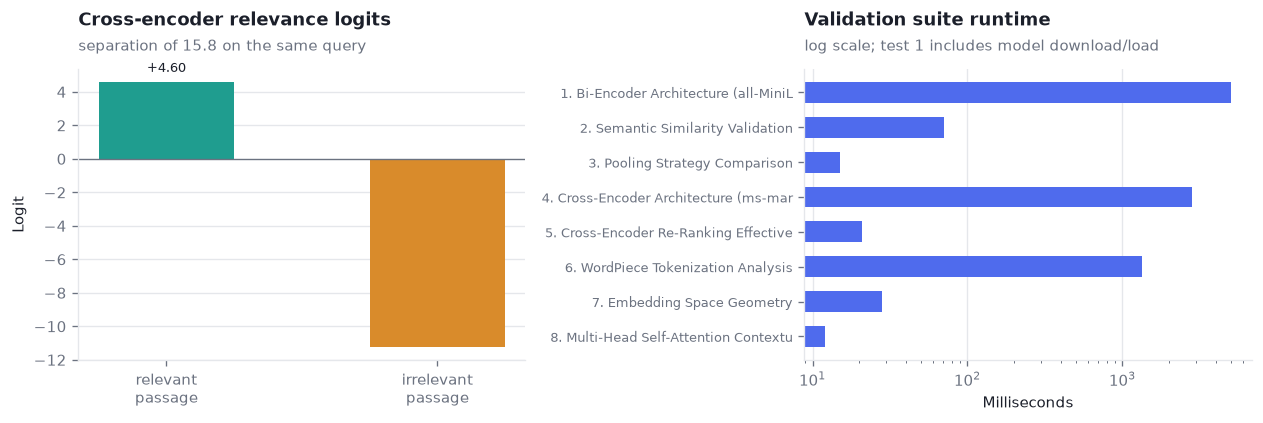

In [36]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.6, 3.6))

bars = ax1.bar(["relevant\npassage", "irrelevant\npassage"], [ce["relevant_score"], ce["irrelevant_score"]],
               color=[C_STAGE2, C_WARN], width=0.5)
style(ax1, "Cross-encoder relevance logits",
      f"separation of {ce['relevant_score'] - ce['irrelevant_score']:.1f} on the same query", "Logit")
ax1.axhline(0, color=MUTED, lw=0.8)
for b in bars:
    h = b.get_height()
    ax1.annotate(f"{h:+.2f}", (b.get_x() + b.get_width() / 2, h + (0.6 if h > 0 else -1.6)),
                 ha="center", fontsize=8, color=INK)

names = [t["name"].replace(" (", "\n(") for t in arch["tests"]]
ax2.barh(range(len(names)), [t["duration_ms"] for t in arch["tests"]], color=C_STAGE1, height=0.6)
ax2.set_yticks(range(len(names)), [f"{i + 1}. {t['name'][:34]}" for i, t in enumerate(arch["tests"])],
               fontsize=8)
ax2.invert_yaxis()
ax2.set_xscale("log")
style(ax2, "Validation suite runtime", "log scale; test 1 includes model download/load", None)
ax2.set_xlabel("Milliseconds")
ax2.xaxis.grid(True)
ax2.yaxis.grid(False)

plt.tight_layout()
plt.show()

<a id="13"></a>
## 13. Conclusions and future work

### What the project demonstrates

1. **A two-stage neural retrieval pipeline measurably beats dense retrieval alone.** Cross-encoder
   re-ranking lifts Document Recall@1 from **31.5% to 45.0%** (+13.5 points, a 43% relative gain) and
   Document MRR from **0.374 to 0.477** over 200 LegalBench-RAG queries — exactly the behaviour the
   architecture predicts, since joint query-document attention can resolve distinctions that independent
   Siamese encodings cannot.
2. **The trade-off is quantified, not assumed.** Re-ranking adds roughly an order of magnitude of latency
   over Stage 1 for a pool of ~60 candidates (measured in Section 7), which is why it is confined to
   re-ranking rather than used for search.
3. **Distilled encoders are enough.** Two 6-layer, ~22M-parameter MiniLM models run the entire pipeline on
   CPU, with no fine-tuning and no proprietary embedding API.
4. **Structure-aware chunking is implemented end-to-end.** The parser recovers articles, sections,
   recitals, definitions and schedules; children carry structural breadcrumbs for retrieval while the LLM
   receives whole parent clauses, de-duplicated and capped.
5. **Grounding is enforced architecturally**, through context-bounded prompting, span-level citations and an
   explicit refusal path (demonstrated in Section 8).

### Honest limitations

* **Snippet-level recall did not improve with re-ranking** (13.0% → 12.0% at k=1). The benchmark index was
  built from flat gold snippets rather than through the structural parent-child pipeline, so exact-span
  precision is bounded by the chunking, not by the re-ranker. Re-ingesting the full corpus through
  `ParentChildSplitter` is the single highest-value next experiment.
* **The saved LLM-as-a-judge numbers are invalid.** The judge model (`llama-3.1-8b-instant`) was
  decommissioned, every judge call 404'd, and the error-handling path silently scored those failures as 1
  (Sections 10 and 11). The ablation must be re-run with a current judge, and
  `parse_judge_json()` should treat an unparseable judge response as *missing*, never as a pass.
* **Unscoped retrieval hit rate is low (26-30%)** over 695 contracts. The product mitigates this by scoping
  queries to a selected document and by fan-out for comparisons, but global search over the whole corpus
  remains weak.
* **Evaluation sample sizes are modest** (200 retrieval queries, 50 faithfulness queries, 15 multi-document
  queries), and the generation path depends on a hosted LLM, so absolute generation numbers are not
  reproducible to the digit.

### Future work

1. **Domain-adaptive pre-training (DAPT)** — continue pre-training the bi-encoder on unlabelled contract
   text, then fine-tune on LegalBench pairs; the embedding-geometry results suggest clear headroom.
2. **Structural re-ingestion of the benchmark corpus** through the parent-child pipeline, to test the
   snippet-recall hypothesis above directly.
3. **ColBERT-style late interaction**, to recover some of the cross-encoder's accuracy at bi-encoder cost.
4. **Hybrid retrieval** — BM25 fused with dense scores, since legal queries carry exact identifiers (party
   names, section numbers) that lexical matching handles better than any embedding.
5. **Layout-aware document understanding** (LayoutLMv3 / Donut) for multi-column reading order, merged-cell
   tables and signature blocks, building on the OCR and table extraction already in place.

## Appendix — repository layout and reproduction

```
synapse-rag/
├── python/                              # FastAPI backend (deep learning pipeline)
│   ├── app/
│   │   ├── embeddings.py                # Bi-encoder: all-MiniLM-L6-v2, 384-d, L2-normalised
│   │   ├── cross_encoder.py             # Cross-encoder re-ranker + sigmoid confidence
│   │   ├── rag.py                       # Retrieval, fan-out, context formatting, prompts, LLM
│   │   ├── chunking/
│   │   │   └── parent_child_splitter.py # Parent clauses + breadcrumbed child windows
│   │   ├── parsers/                     # PDF / DOCX / OCR / tables / legal hierarchy
│   │   └── routes/                      # chat, retrieve, documents, upload
│   ├── scripts/
│   │   ├── ingest.py                    # Build the Qdrant index from LegalBench-RAG
│   │   └── test_dl_architectures.py     # Architecture validation suite (Section 12)
│   ├── tests/                           # pytest unit tests for the parsers
│   └── qdrant_db/                       # Embedded Qdrant store (7,662 child vectors)
├── scripts/
│   ├── evaluate_retrieval.py            # Retrieval metrics + re-ranking lift (Section 9)
│   ├── evaluate_faithfulness.py         # 2x2 faithfulness ablation (Section 10)
│   └── evaluate_multidoc.py             # Multi-document fan-out benchmark (Section 11)
├── results/                             # Saved metrics and console logs loaded by this notebook
├── notebooks/                           # This notebook
├── report/                              # LaTeX report and figures
└── src/                                 # Next.js 16 frontend (chat UI, citations, uploads)
```

### Reproducing everything in this notebook

```bash
# 1. Backend environment
cd python && python -m venv venv && venv\Scripts\activate
pip install -r requirements.txt
pip install ipykernel nbconvert matplotlib      # notebook execution only

# 2. Build the vector index (only needed once; rebuilds python/qdrant_db from scratch)
python scripts/ingest.py

# 3. Validate the transformer architectures          -> Section 12
python scripts/test_dl_architectures.py

# 4. Retrieval metrics and re-ranking lift           -> Section 9
cd .. && python scripts/evaluate_retrieval.py --limit 200 --seed 0 --k 20

# 5. Faithfulness ablation (set a current judge model first)  -> Section 10
python scripts/evaluate_faithfulness.py --limit 50 --scoped --rerank

# 6. Multi-document fan-out benchmark                -> Section 11
python scripts/evaluate_multidoc.py

# 7. Run this notebook (stop the FastAPI backend first — Qdrant takes an exclusive lock)
jupyter lab notebooks/synapse_rag_demo.ipynb
```

Running the full application requires both servers: `npm run dev` for the Next.js frontend on port 3000,
and `uvicorn app.main:app --port 8001 --reload` from `python/` for the FastAPI backend.